# Project 47 - Automatic Defect Counting & Spatial Density Estimation from CT Volumes

Run the cells **top to bottom** (Kernel -> Restart & Run All). Default = 6-volume **pilot** (`N_VOLUMES = 6`). Set `N_VOLUMES = 350` in the first code cell for the full dataset. Paths are fixed in the first code cell.

In [2]:
# =====================================================================
# PROJECT 47 - IMPORTS + CENTRAL CONFIGURATION (all settings and ALL paths live here)
# =====================================================================
import json
import math
import shutil
import hashlib
import random
import time
import warnings
from collections import OrderedDict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage
from skimage.filters import threshold_otsu
from skimage.metrics import structural_similarity

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

try:
    from IPython.display import display
except ImportError:  # plain-python fallback
    def display(obj):
        print(obj)

torch.set_default_dtype(torch.float32)

# ---------------------------------------------------------------------
# FIXED WINDOWS PATHS (single source of truth - never hard-coded elsewhere)
# ---------------------------------------------------------------------
DATA_ROOT = Path(r"C:\Users\bpgod\Downloads\proejct-47\data")

TRAIN_DIR = DATA_ROOT / "training-data"
TEST_DIR = DATA_ROOT / "testing-data"
VAL_DIR = DATA_ROOT / "validation-data"

PROJECT_ROOT = DATA_ROOT.parent
OUTPUT_DIR = PROJECT_ROOT / "outputs"

for directory in [TRAIN_DIR, TEST_DIR, VAL_DIR, OUTPUT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

# Outputs (checkpoints, logs, figures, results, predictions) live ONLY under OUTPUT_DIR
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
LOG_DIR = OUTPUT_DIR / "logs"
FIG_DIR = OUTPUT_DIR / "figures"
RESULT_DIR = OUTPUT_DIR / "results"
PRED_DIR = OUTPUT_DIR / "predictions"
for directory in [CHECKPOINT_DIR, LOG_DIR, FIG_DIR, RESULT_DIR, PRED_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

SPLIT_DIRS = {"train": TRAIN_DIR, "val": VAL_DIR, "test": TEST_DIR}
MANIFEST_PATH = DATA_ROOT / "dataset_manifest.json"
GENERATED_ITEMS = ("volumes", "density_maps", "pore_masks", "centroids", "metadata.csv")


def assert_writable(directory):
    probe = Path(directory) / ".write_test"
    try:
        probe.write_text("ok")
        probe.unlink()
    except OSError as err:
        raise PermissionError(f"Directory is not writable: {directory} ({err})") from err


for _d in [DATA_ROOT, *SPLIT_DIRS.values(), OUTPUT_DIR, CHECKPOINT_DIR, LOG_DIR, FIG_DIR, RESULT_DIR, PRED_DIR]:
    assert_writable(_d)
# outputs must never be written inside a dataset split folder
assert not any(OUTPUT_DIR.is_relative_to(d) for d in SPLIT_DIRS.values()), "OUTPUT_DIR must not be inside a data split folder"

# ---------------------------------------------------------------------
# DATASET SWITCH  (the ONLY change needed to go from pilot to full dataset)
# ---------------------------------------------------------------------
N_VOLUMES = 350                      # <<< 6 = pilot (default).  Set to 350 for the full dataset.
OVERWRITE_EXISTING_DATA = False    # never replace an existing dataset unless this is True

SEED = 47
VOLUME_SHAPE = (128, 128, 128)     # (z, y, x)
COUNT_RANGE = (5, 100)
COUNT_BINS = ((5, 35), (36, 68), (69, 100))
COUNT_BIN_NAMES = ("low", "mid", "high")
RADIUS_RANGE = (2.0, 8.0)          # semi-axis range in voxels (spheres and ellipsoids)
SPHERE_FRACTION = 0.3              # fraction of pores that are exact spheres
ELLIPSOID_AXIS_JITTER = (0.75, 1.25)
REGIMES = ("uniform", "clustered", "sparse")
BORDER_MARGIN = 2.0                # centroids are kept this far from the volume faces
SPARSE_MIN_SEPARATION = 17.0       # > 2 * max radius, so sparse pores cannot touch
SPARSE_MAX_ATTEMPTS = 2000
CLUSTER_COUNT_RANGE = (2, 5)       # inclusive
CLUSTER_SPREAD_RANGE = (5.0, 12.0)  # Gaussian std of pores around a cluster centre (voxels)

MATRIX_INTENSITY_RANGE = (0.70, 0.90)   # matrix is BRIGHTER than pores
PORE_INTENSITY_RANGE = (0.10, 0.30)
EDGE_BLUR_SIGMA = 0.7                   # partial-volume blur of pore edges (voxels)
NOISE_LEVELS = {                        # controllable Gaussian + Poisson noise
    "low": {"gaussian_sigma": 0.02, "poisson_photons": 2000},
    "medium": {"gaussian_sigma": 0.05, "poisson_photons": 500},
    "high": {"gaussian_sigma": 0.10, "poisson_photons": 150},
}
NOISE_LEVEL_NAMES = tuple(NOISE_LEVELS)  # poisson_photons = 0 disables Poisson noise

DENSITY_SIGMA = 3.5                # Gaussian target sigma (voxels)
DENSITY_TRUNCATE = 3.0             # kernel support in sigmas
DENSITY_SUM_ATOL = 1e-3            # tolerance for density.sum() == true_count (float32 storage)
VOXEL_SPACING_MM = (1.0, 1.0, 1.0)
SPLIT_FRACTIONS = {"train": 0.70, "val": 0.15, "test": 0.15}

# ---------------------------------------------------------------------
# PREPROCESSING / PATCHES
# ---------------------------------------------------------------------
PATCH_SIZE = 64
TARGET_SCALE = 1000.0              # applied ONLY when building training targets
POSITIVE_PATCH_FRACTION = 0.5      # balanced sampling: share of pore-containing patches
POSITIVE_PATCH_MIN_COUNT = 0.5     # patch GT count >= this -> "pore" patch
EMPTY_PATCH_MAX_COUNT = 0.05       # patch GT count <= this -> "empty" patch
PATCH_SEARCH_TRIES = 24
VOLUME_CACHE_SIZE = 12             # volumes kept in CPU RAM (never the whole dataset, never on GPU)
AUGMENT_INTENSITY = True
AUG_SCALE = 0.05
AUG_SHIFT_STD = 0.02
AUG_NOISE_STD_MAX = 0.02

# ---------------------------------------------------------------------
# MODEL / TRAINING
# ---------------------------------------------------------------------
BASE_CHANNELS = 16                 # 16-32-64 encoder; lower to 8 if GPU memory is tight
BOTTLENECK_DILATIONS = (2, 4)
FINAL_BIAS_INIT = -6.0             # critical: prevents massive background accumulation
LEARNING_RATE = 1e-4
BATCH_SIZE = 2
NUM_WORKERS = 0                    # critical on Windows: no DataLoader worker processes
LAMBDA_COUNT = 0.5
COUNT_LOSS_NORM = 10.0             # counts are divided by this inside the count loss
GRAD_CLIP_NORM = 5.0
LR_PLATEAU_PATIENCE = 5
EARLY_STOP_PATIENCE = 15
EARLY_STOP_MIN_DELTA = 1e-3
PILOT_MODE = N_VOLUMES < 50
MAX_EPOCHS = 2 if PILOT_MODE else 100              # pilot = smoke test only
TRAIN_PATCHES_PER_VOLUME = 2 if PILOT_MODE else 4  # patches drawn per train volume per epoch
RUN_TRAINING = True                # False -> load the saved best checkpoint instead
BACKGROUND_WARN_COUNT = 25.0       # diagnostic warning threshold for untrained background count
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------------------------------------------------------------
# INFERENCE / EVALUATION
# ---------------------------------------------------------------------
INFER_PATCH_SIZE = 64
INFER_OVERLAP = 0.5                # stride = patch * (1 - overlap)
INFER_BATCH_SIZE = 4
HANN_FLOOR = 0.05
REGION_GRID = (4, 4, 4)            # sub-regions for local density / Pearson
CC_MIN_COMPONENT_VOXELS = 10
CC_CONNECTIVITY = 1                # 1 = 6-neighbourhood, 2 = 18, 3 = 26
CC_PRESMOOTH_SIGMA = 0.0           # 0 = pure Otsu on the raw noisy volume

RUN_EXPERIMENT_A = True            # noise-level sweep (re-uses trained model, cheap)
RUN_EXPERIMENT_C = False           # sigma sensitivity (RETRAINS one model per sigma - expensive)
RUN_EXPERIMENT_D = False           # count extrapolation (RETRAINS one model - expensive)
EXP_A_NOISE_LEVELS = {
    "none": {"gaussian_sigma": 0.0, "poisson_photons": 0},
    "low": NOISE_LEVELS["low"],
    "medium": NOISE_LEVELS["medium"],
    "high": NOISE_LEVELS["high"],
    "very_high": {"gaussian_sigma": 0.15, "poisson_photons": 80},
}
EXP_A_MAX_VOLUMES = 20              # cap on test volumes used in experiment A (5 inference passes each)
EXP_C_SIGMAS = (3.0, 3.5, 4.0)
EXP_D_TRAIN_MAX = 60               # train on counts <= 60, test on counts > 60


def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_global_seed(SEED)

print("DATA_ROOT  :", DATA_ROOT.resolve())
print("TRAIN_DIR  :", TRAIN_DIR.resolve())
print("VAL_DIR    :", VAL_DIR.resolve())
print("TEST_DIR   :", TEST_DIR.resolve())
print("OUTPUT_DIR :", OUTPUT_DIR.resolve())
print(f"N_VOLUMES={N_VOLUMES}  PILOT_MODE={PILOT_MODE}  device={DEVICE}  num_workers={NUM_WORKERS}")

DATA_ROOT  : C:\Users\bpgod\Downloads\proejct-47\data
TRAIN_DIR  : C:\Users\bpgod\Downloads\proejct-47\data\training-data
VAL_DIR    : C:\Users\bpgod\Downloads\proejct-47\data\validation-data
TEST_DIR   : C:\Users\bpgod\Downloads\proejct-47\data\testing-data
OUTPUT_DIR : C:\Users\bpgod\Downloads\proejct-47\outputs
N_VOLUMES=350  PILOT_MODE=False  device=cuda  num_workers=0


## Step 1 - Synthetic 3D CT data generation (primitives)

In [4]:
# =====================================================================
# STEP 1 - synthetic CT generation primitives (specs, splits, pore placement, rendering)
# =====================================================================
def make_rng(*keys):
    # independent, reproducible stream per (purpose, volume index)
    return np.random.default_rng([SEED] + [int(k) for k in keys])


def build_volume_specs(n_volumes):
    # regimes cycle uniform/clustered/sparse; count bins cycle within each regime
    rng = make_rng(0)
    seen = {r: 0 for r in REGIMES}
    specs = []
    for i in range(n_volumes):
        regime = REGIMES[i % len(REGIMES)]
        k = seen[regime]
        seen[regime] += 1
        bin_idx = k % len(COUNT_BINS)
        lo, hi = COUNT_BINS[bin_idx]
        specs.append({
            "index": i,
            "volume_id": f"vol_{i:04d}",
            "regime": regime,
            "count_bin": bin_idx,
            "true_count": int(rng.integers(lo, hi + 1)),
            "noise_level": NOISE_LEVEL_NAMES[int(rng.integers(len(NOISE_LEVEL_NAMES)))],
        })
    return specs


def split_sizes(n):
    # 350 -> 245 / 52 / 53 exactly.  Tiny pilots (n < 20) -> n-2 / 1 / 1.
    if n < 3:
        raise ValueError("N_VOLUMES must be at least 3 (one volume per split).")
    if n < 20:
        return {"train": n - 2, "val": 1, "test": 1}
    n_train = int(round(SPLIT_FRACTIONS["train"] * n))
    n_val = int(math.floor(SPLIT_FRACTIONS["val"] * n + 1e-9))
    return {"train": n_train, "val": n_val, "test": n - n_train - n_val}


def assign_splits(specs):
    # Stratified by (regime, count bin).  Strata are listed one after another (shuffled inside),
    # then a deterministic largest-deficit apportionment deals the split labels along that list, so
    # every stratum receives a near-proportional share.  Fallback for tiny strata: the same global
    # apportionment simply spreads the leftovers; exact split sizes are always honoured.
    n = len(specs)
    sizes = split_sizes(n)
    names = ["train", "val", "test"]
    target = np.array([sizes[s] for s in names], dtype=float)
    rng = make_rng(1)
    strata = {}
    for s in specs:
        strata.setdefault((s["regime"], s["count_bin"]), []).append(s["index"])
    ordered = []
    for key in sorted(strata):
        idx = np.array(strata[key])
        rng.shuffle(idx)
        ordered.extend(idx.tolist())
    assigned = np.zeros(3)
    split_of = {}
    for step, vol_index in enumerate(ordered):
        deficit = target / n * (step + 1) - assigned
        deficit[assigned >= target] = -np.inf  # never exceed an exact split size
        k = int(np.argmax(deficit))
        split_of[vol_index] = names[k]
        assigned[k] += 1
    assert all(int(assigned[i]) == sizes[names[i]] for i in range(3)), "split sizes not honoured"
    return split_of


def random_rotation_matrices(rng, n):
    # uniformly random 3D rotations from random unit quaternions
    q = rng.normal(size=(n, 4))
    q /= np.linalg.norm(q, axis=1, keepdims=True)
    w, x, y, z = q.T
    R = np.empty((n, 3, 3))
    R[:, 0, 0] = 1 - 2 * (y * y + z * z); R[:, 0, 1] = 2 * (x * y - z * w); R[:, 0, 2] = 2 * (x * z + y * w)
    R[:, 1, 0] = 2 * (x * y + z * w); R[:, 1, 1] = 1 - 2 * (x * x + z * z); R[:, 1, 2] = 2 * (y * z - x * w)
    R[:, 2, 0] = 2 * (x * z - y * w); R[:, 2, 1] = 2 * (y * z + x * w); R[:, 2, 2] = 1 - 2 * (x * x + y * y)
    return R


def sample_semi_axes(rng, n):
    # spheres (equal axes) or ellipsoids; every semi-axis stays inside RADIUS_RANGE
    base = rng.uniform(RADIUS_RANGE[0], RADIUS_RANGE[1], size=n)
    jitter = rng.uniform(ELLIPSOID_AXIS_JITTER[0], ELLIPSOID_AXIS_JITTER[1], size=(n, 3))
    axes = np.clip(base[:, None] * jitter, RADIUS_RANGE[0], RADIUS_RANGE[1])
    spheres = rng.random(n) < SPHERE_FRACTION
    axes[spheres] = base[spheres, None]
    return axes


def _bounds(shape):
    lo = BORDER_MARGIN
    hi = np.array(shape, dtype=float) - 1.0 - BORDER_MARGIN
    return lo, hi


def sample_uniform_centroids(rng, n, shape):
    lo, hi = _bounds(shape)
    return rng.uniform(lo, hi, size=(n, 3))


def sample_clustered_centroids(rng, n, shape):
    # Gaussian-mixture style: pores scattered around a few centres; overlap is allowed on purpose
    lo, hi = _bounds(shape)
    n_clusters = int(rng.integers(CLUSTER_COUNT_RANGE[0], CLUSTER_COUNT_RANGE[1] + 1))
    n_clusters = max(1, min(n_clusters, n // 3))
    centers = rng.uniform(lo + 8.0, hi - 8.0, size=(n_clusters, 3))
    weights = rng.dirichlet(np.full(n_clusters, 2.0))
    assign = rng.choice(n_clusters, size=n, p=weights)
    assign[:n_clusters] = np.arange(n_clusters)  # every cluster gets at least one pore
    spreads = rng.uniform(CLUSTER_SPREAD_RANGE[0], CLUSTER_SPREAD_RANGE[1], size=n_clusters)
    pts = np.empty((n, 3))
    for j in range(n):
        c = assign[j]
        for _ in range(50):
            p = centers[c] + rng.normal(0.0, spreads[c], size=3)
            if np.all(p >= lo) and np.all(p <= hi):
                break
        else:
            p = np.clip(p, lo, hi)
        pts[j] = p
    return pts, n_clusters


def sample_sparse_centroids(rng, n, shape, min_sep):
    # random sequential placement with a minimum centroid separation; if it jams, the separation
    # is relaxed by 5 % (the final value is stored in the metadata)
    lo, hi = _bounds(shape)
    pts = np.empty((n, 3))
    k, attempts, sep = 0, 0, float(min_sep)
    while k < n:
        c = rng.uniform(lo, hi, size=3)
        if k == 0 or np.min(np.linalg.norm(pts[:k] - c, axis=1)) >= sep:
            pts[k] = c
            k += 1
            attempts = 0
        else:
            attempts += 1
            if attempts >= SPARSE_MAX_ATTEMPTS:
                sep *= 0.95
                attempts = 0
    return pts, sep


def paint_pore_mask(shape, centroids, axes, rotations):
    # union of (rotated) ellipsoids, painted inside small bounding boxes
    mask = np.zeros(shape, dtype=bool)
    shape_arr = np.array(shape)
    for c, ax, R in zip(centroids, axes, rotations):
        half = int(math.ceil(float(ax.max()))) + 1
        base = np.floor(c).astype(int)
        lo = np.maximum(base - half, 0)
        hi = np.minimum(base + half + 1, shape_arr)
        if np.any(hi <= lo):
            continue
        gz, gy, gx = np.ogrid[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]]
        d = np.stack(np.broadcast_arrays(gz - c[0], gy - c[1], gx - c[2]), axis=-1)
        q = d @ R  # coordinates in the ellipsoid frame (R^T d)
        inside = ((q / ax) ** 2).sum(axis=-1) <= 1.0
        mask[lo[0]:hi[0], lo[1]:hi[1], lo[2]:hi[2]] |= inside
    return mask


def render_ct(mask, matrix_intensity, pore_intensity, blur_sigma, gaussian_sigma, poisson_photons, rng):
    # matrix bright, pores dark; partial-volume blur; Poisson then Gaussian noise
    soft = mask.astype(np.float32)
    if blur_sigma > 0:
        soft = ndimage.gaussian_filter(soft, blur_sigma)
    clean = matrix_intensity + (pore_intensity - matrix_intensity) * soft.astype(np.float64)
    noisy = clean
    if poisson_photons and poisson_photons > 0:
        noisy = rng.poisson(np.clip(clean, 0.0, None) * poisson_photons) / float(poisson_photons)
    if gaussian_sigma and gaussian_sigma > 0:
        noisy = noisy + rng.normal(0.0, gaussian_sigma, size=noisy.shape)
    return noisy.astype(np.float32)


def write_centroid_csv(path, centroids, axes):
    df = pd.DataFrame({
        "pore_id": np.arange(len(centroids)),
        "z": centroids[:, 0], "y": centroids[:, 1], "x": centroids[:, 2],
        "semi_axis_a": axes[:, 0], "semi_axis_b": axes[:, 1], "semi_axis_c": axes[:, 2],
    })
    df.to_csv(path, index=False)


print("Step 1 primitives defined.")

Step 1 primitives defined.


## Step 2 - Ground-truth density maps (exact count conservation)

In [6]:
# =====================================================================
# STEP 2 - ground-truth density maps with exact count conservation
# =====================================================================
def _axis_window(c, n, sigma, truncate):
    # 1D Gaussian weights over the VISIBLE part of the +-truncate*sigma support, renormalised to sum 1.
    # Because the 3D kernel is separable, the 3D kernel then also sums to exactly 1 (even if truncated
    # by the volume boundary).
    reach = truncate * sigma
    lo = max(0, int(math.ceil(c - reach)))
    hi = min(n, int(math.floor(c + reach)) + 1)
    assert hi > lo, f"centroid {c} has no visible support in axis of length {n}"
    idx = np.arange(lo, hi, dtype=np.float64)
    w = np.exp(-0.5 * ((idx - c) / sigma) ** 2)
    return lo, hi, w / w.sum()


def gaussian_density_map(centroids, shape, sigma=DENSITY_SIGMA, truncate=DENSITY_TRUNCATE, crop=None, dtype=np.float32):
    """Sum of unit-mass 3D Gaussians, one per centroid (z, y, x in voxels).

    crop = ((z0, z1), (y0, y1), (x0, x1)) returns only that window of the FULL-volume map, so a kernel
    that crosses the window edge contributes only its true partial mass (used for patch targets).
    """
    if crop is None:
        crop = tuple((0, int(s)) for s in shape)
    out = np.zeros(tuple(hi - lo for lo, hi in crop), dtype=np.float64)
    for c in np.asarray(centroids, dtype=np.float64).reshape(-1, 3):
        parts, slices, visible = [], [], True
        for a in range(3):
            lo, hi, w = _axis_window(c[a], shape[a], sigma, truncate)
            clo, chi = crop[a]
            ilo, ihi = max(lo, clo), min(hi, chi)
            if ilo >= ihi:
                visible = False
                break
            parts.append(w[ilo - lo:ihi - lo])
            slices.append(slice(ilo - clo, ihi - clo))
        if visible:
            out[tuple(slices)] += parts[0][:, None, None] * parts[1][None, :, None] * parts[2][None, None, :]
    return out.astype(dtype)


def check_generated_sample(volume, density, mask, centroids, true_count):
    assert volume.shape == tuple(VOLUME_SHAPE), f"volume shape {volume.shape}"
    assert density.shape == tuple(VOLUME_SHAPE), f"density shape {density.shape}"
    assert mask.shape == tuple(VOLUME_SHAPE), f"mask shape {mask.shape}"
    assert volume.dtype == np.float32 and density.dtype == np.float32
    assert len(centroids) == true_count, "centroid count != metadata count"
    assert np.isfinite(volume).all() and np.isfinite(density).all(), "NaN/Inf found"
    total = float(density.sum(dtype=np.float64))
    assert abs(total - true_count) <= DENSITY_SUM_ATOL, f"density integral {total} != count {true_count}"


# quick self-test of count conservation, including kernels truncated at the boundary
_test_c = np.array([[0.0, 0.0, 0.0], [127.0, 127.0, 127.0], [64.3, 10.2, 120.9], [2.0, 64.0, 64.0]])
_test_map = gaussian_density_map(_test_c, VOLUME_SHAPE, dtype=np.float64)
assert abs(_test_map.sum() - len(_test_c)) < 1e-9, "count conservation failed in float64"
print(f"Step 2 self-test OK: 4 pores (2 at corners) integrate to {_test_map.sum():.12f}")

Step 2 self-test OK: 4 pores (2 at corners) integrate to 4.000000000000


## Steps 1-2 execution - generate or reuse the dataset (never overwrites unless `OVERWRITE_EXISTING_DATA = True`)

In [8]:
# =====================================================================
# STEPS 1-2 EXECUTION - generate (or reuse) the dataset in the fixed split folders
# =====================================================================
def dataset_fingerprint():
    cfg = {
        "n_volumes": N_VOLUMES, "seed": SEED, "shape": VOLUME_SHAPE, "count_range": COUNT_RANGE,
        "count_bins": COUNT_BINS, "radius": RADIUS_RANGE, "sphere_fraction": SPHERE_FRACTION,
        "axis_jitter": ELLIPSOID_AXIS_JITTER, "regimes": REGIMES, "border": BORDER_MARGIN,
        "sparse_sep": SPARSE_MIN_SEPARATION, "clusters": CLUSTER_COUNT_RANGE, "spread": CLUSTER_SPREAD_RANGE,
        "matrix": MATRIX_INTENSITY_RANGE, "pore": PORE_INTENSITY_RANGE, "blur": EDGE_BLUR_SIGMA,
        "noise": NOISE_LEVELS, "density_sigma": DENSITY_SIGMA, "truncate": DENSITY_TRUNCATE,
        "fractions": SPLIT_FRACTIONS, "generator_version": 1,
    }
    return hashlib.sha1(json.dumps(cfg, sort_keys=True, default=str).encode()).hexdigest()


def generate_one_volume(spec, split):
    idx, vid, n, regime = spec["index"], spec["volume_id"], spec["true_count"], spec["regime"]
    rng = make_rng(100, idx)
    n_clusters, min_sep = 0, np.nan
    if regime == "uniform":
        centroids = sample_uniform_centroids(rng, n, VOLUME_SHAPE)
    elif regime == "clustered":
        centroids, n_clusters = sample_clustered_centroids(rng, n, VOLUME_SHAPE)
    elif regime == "sparse":
        centroids, min_sep = sample_sparse_centroids(rng, n, VOLUME_SHAPE, SPARSE_MIN_SEPARATION)
    else:
        raise ValueError(f"unknown regime {regime}")
    axes = sample_semi_axes(rng, n)
    rotations = random_rotation_matrices(rng, n)
    mask = paint_pore_mask(VOLUME_SHAPE, centroids, axes, rotations)
    matrix_i = float(rng.uniform(*MATRIX_INTENSITY_RANGE))
    pore_i = float(rng.uniform(*PORE_INTENSITY_RANGE))
    noise = NOISE_LEVELS[spec["noise_level"]]
    volume = render_ct(mask, matrix_i, pore_i, EDGE_BLUR_SIGMA, noise["gaussian_sigma"],
                       noise["poisson_photons"], make_rng(200, idx))
    density = gaussian_density_map(centroids, VOLUME_SHAPE, DENSITY_SIGMA)  # UN-SCALED ground truth
    check_generated_sample(volume, density, mask, centroids, n)

    d = SPLIT_DIRS[split]
    np.save(d / "volumes" / f"{vid}.npy", volume)
    np.save(d / "density_maps" / f"{vid}.npy", density)
    np.save(d / "pore_masks" / f"{vid}.npy", mask.astype(np.uint8))
    write_centroid_csv(d / "centroids" / f"{vid}.csv", centroids, axes)
    return {
        "volume_id": vid, "split": split, "regime": regime, "count_bin": COUNT_BIN_NAMES[spec["count_bin"]],
        "true_count": n, "noise_level": spec["noise_level"],
        "gaussian_noise_sigma": noise["gaussian_sigma"], "poisson_photons": noise["poisson_photons"],
        "matrix_intensity": matrix_i, "pore_intensity": pore_i, "edge_blur_sigma": EDGE_BLUR_SIGMA,
        "density_sigma": DENSITY_SIGMA, "density_sum": float(density.sum(dtype=np.float64)),
        "pore_voxel_fraction": float(mask.mean()), "n_clusters": n_clusters,
        "min_centroid_separation": min_sep, "seed": SEED, "shape": "x".join(map(str, VOLUME_SHAPE)),
    }


def wipe_generated_files():
    # removes ONLY what this notebook creates (never other files in the folders)
    for d in SPLIT_DIRS.values():
        for item in GENERATED_ITEMS:
            p = d / item
            if p.is_dir():
                shutil.rmtree(p)
            elif p.exists():
                p.unlink()
    if MANIFEST_PATH.exists():
        MANIFEST_PATH.unlink()


def prepare_dataset():
    has_meta = {s: (d / "metadata.csv").exists() for s, d in SPLIT_DIRS.items()}
    has_any = any((d / item).exists() for d in SPLIT_DIRS.values() for item in GENERATED_ITEMS)
    fingerprint = dataset_fingerprint()

    if has_any and not OVERWRITE_EXISTING_DATA:
        if MANIFEST_PATH.exists():
            manifest = json.loads(MANIFEST_PATH.read_text())
            if manifest.get("fingerprint") == fingerprint and all(has_meta.values()):
                print("Existing dataset matches the current configuration -> REUSED (nothing written).")
                return "reused"
            raise RuntimeError(
                "An existing dataset was found in DATA_ROOT but it was generated with a different "
                f"configuration (it has {manifest.get('n_volumes')} volumes; current N_VOLUMES={N_VOLUMES}). "
                "Refusing to overwrite. Set OVERWRITE_EXISTING_DATA = True to replace it, or move it away.")
        if all(has_meta.values()):
            print("WARNING: existing dataset without a manifest -> ADOPTED as-is (no files written). "
                  "It will be validated below.")
            return "adopted"
        raise RuntimeError("Partial/unknown dataset files found in the split folders. Refusing to overwrite. "
                           "Set OVERWRITE_EXISTING_DATA = True to wipe the notebook-generated files and regenerate.")

    if has_any and OVERWRITE_EXISTING_DATA:
        print("OVERWRITE_EXISTING_DATA=True -> removing previously generated dataset files ...")
        wipe_generated_files()

    specs = build_volume_specs(N_VOLUMES)
    split_of = assign_splits(specs)
    for d in SPLIT_DIRS.values():
        for sub in ("volumes", "density_maps", "pore_masks", "centroids"):
            (d / sub).mkdir(parents=True, exist_ok=True)

    rows = {s: [] for s in SPLIT_DIRS}
    t0 = time.time()
    for spec in specs:
        split = split_of[spec["index"]]
        rows[split].append(generate_one_volume(spec, split))
        if (spec["index"] + 1) % 10 == 0 or spec["index"] + 1 == len(specs):
            print(f"  generated {spec['index'] + 1}/{len(specs)} volumes ({time.time() - t0:.0f}s)")
    for split, d in SPLIT_DIRS.items():
        pd.DataFrame(rows[split]).to_csv(d / "metadata.csv", index=False)
    MANIFEST_PATH.write_text(json.dumps({"fingerprint": fingerprint, "n_volumes": N_VOLUMES, "seed": SEED,
                                         "sizes": {s: len(r) for s, r in rows.items()}}, indent=2))
    return "generated"


DATASET_STATUS = prepare_dataset()
print("Dataset status:", DATASET_STATUS)

  generated 10/350 volumes (7s)
  generated 20/350 volumes (13s)
  generated 30/350 volumes (23s)
  generated 40/350 volumes (30s)
  generated 50/350 volumes (36s)
  generated 60/350 volumes (43s)
  generated 70/350 volumes (50s)
  generated 80/350 volumes (56s)
  generated 90/350 volumes (63s)
  generated 100/350 volumes (70s)
  generated 110/350 volumes (77s)
  generated 120/350 volumes (83s)
  generated 130/350 volumes (90s)
  generated 140/350 volumes (96s)
  generated 150/350 volumes (103s)
  generated 160/350 volumes (110s)
  generated 170/350 volumes (116s)
  generated 180/350 volumes (123s)
  generated 190/350 volumes (129s)
  generated 200/350 volumes (136s)
  generated 210/350 volumes (142s)
  generated 220/350 volumes (149s)
  generated 230/350 volumes (156s)
  generated 240/350 volumes (162s)
  generated 250/350 volumes (169s)
  generated 260/350 volumes (175s)
  generated 270/350 volumes (182s)
  generated 280/350 volumes (188s)
  generated 290/350 volumes (195s)
  generat

## Dataset validation

In [10]:
# =====================================================================
# DATASET VALIDATION - reads back every saved file and asserts the Step 1-2 requirements
# =====================================================================
def validate_dataset():
    rows, seen = [], {}
    for split, d in SPLIT_DIRS.items():
        meta = pd.read_csv(d / "metadata.csv")
        for row in meta.to_dict("records"):
            vid = row["volume_id"]
            assert vid not in seen, f"{vid} appears in both '{seen.get(vid)}' and '{split}'"
            seen[vid] = split
            assert row["split"] == split, f"{vid}: metadata split mismatch"
            p_vol, p_den = d / "volumes" / f"{vid}.npy", d / "density_maps" / f"{vid}.npy"
            p_mask, p_cent = d / "pore_masks" / f"{vid}.npy", d / "centroids" / f"{vid}.csv"
            for p in (p_vol, p_den, p_mask, p_cent):
                assert p.exists(), f"missing file {p}"
            vol, den, mask = np.load(p_vol), np.load(p_den), np.load(p_mask)
            assert vol.shape == tuple(VOLUME_SHAPE) and den.shape == tuple(VOLUME_SHAPE), f"{vid}: shape"
            assert mask.shape == tuple(VOLUME_SHAPE), f"{vid}: mask shape"
            assert vol.dtype == np.float32 and den.dtype == np.float32, f"{vid}: dtype"
            assert np.isfinite(vol).all() and np.isfinite(den).all(), f"{vid}: NaN/Inf"
            n_cent = len(pd.read_csv(p_cent))
            assert n_cent == int(row["true_count"]), f"{vid}: centroid rows {n_cent} != metadata count"
            integral = float(den.sum(dtype=np.float64))
            assert abs(integral - row["true_count"]) <= DENSITY_SUM_ATOL, f"{vid}: integral {integral}"
            rows.append({"volume_id": vid, "split": split, "regime": row["regime"], "count_bin": row["count_bin"],
                         "true_count": int(row["true_count"]), "density_integral": integral,
                         "abs_count_error": abs(integral - row["true_count"])})
    return pd.DataFrame(rows)


def print_dataset_overview(df):
    print("Resolved split folders:")
    for s, d in SPLIT_DIRS.items():
        print(f"  {s:5s}: {d.resolve()}  ({int((df.split == s).sum())} volumes)")
    print(f"  outputs: {OUTPUT_DIR.resolve()}")
    print(f"Total volumes: {len(df)}")
    print("\nVolumes per split x regime:")
    print(pd.crosstab(df["split"], df["regime"]))
    print("\nVolumes per split x count bin:")
    print(pd.crosstab(df["split"], df["count_bin"]))


DATASET_CHECK = validate_dataset()
print_dataset_overview(DATASET_CHECK)
print(f"\nAll checks passed. Max |density integral - true count| over dataset = "
      f"{DATASET_CHECK['abs_count_error'].max():.2e}  (tolerance {DENSITY_SUM_ATOL})")
if N_VOLUMES == 350 or len(DATASET_CHECK) == 350:
    sizes = DATASET_CHECK["split"].value_counts().to_dict()
    assert sizes == {"train": 245, "val": 52, "test": 53}, f"unexpected split sizes {sizes}"

Resolved split folders:
  train: C:\Users\bpgod\Downloads\proejct-47\data\training-data  (245 volumes)
  val  : C:\Users\bpgod\Downloads\proejct-47\data\validation-data  (52 volumes)
  test : C:\Users\bpgod\Downloads\proejct-47\data\testing-data  (53 volumes)
  outputs: C:\Users\bpgod\Downloads\proejct-47\outputs
Total volumes: 350

Volumes per split x regime:
regime  clustered  sparse  uniform
split                             
test           18      17       18
train          82      81       82
val            17      18       17

Volumes per split x count bin:
count_bin  high  low  mid
split                    
test         17   18   18
train        81   81   83
val          18   18   16

All checks passed. Max |density integral - true count| over dataset = 3.82e-08  (tolerance 0.001)


## Step 3 - Preprocessing, patches, augmentation

In [12]:
# =====================================================================
# STEP 3 - preprocessing, patch extraction, augmentation, datasets
# =====================================================================
def load_records(split):
    # reads metadata.csv of the split folder and attaches absolute file paths
    d = SPLIT_DIRS[split]
    records = []
    for row in pd.read_csv(d / "metadata.csv").to_dict("records"):
        vid = row["volume_id"]
        assert row["split"] == split, f"{vid} listed in the wrong split folder"
        row.update({
            "path_volume": d / "volumes" / f"{vid}.npy",
            "path_density": d / "density_maps" / f"{vid}.npy",
            "path_mask": d / "pore_masks" / f"{vid}.npy",
            "path_centroids": d / "centroids" / f"{vid}.csv",
        })
        records.append(row)
    return records


def load_centroids(rec):
    return pd.read_csv(rec["path_centroids"])[["z", "y", "x"]].to_numpy(dtype=np.float64)


def cylindrical_fov_mask(shape, radius_fraction=0.98):
    # optional example FOV (circular in-plane, full along z); pass any bool array of VOLUME_SHAPE instead
    _, ny, nx = shape
    yy, xx = np.ogrid[:ny, :nx]
    r = radius_fraction * min(ny, nx) / 2.0
    disc = (yy - (ny - 1) / 2.0) ** 2 + (xx - (nx - 1) / 2.0) ** 2 <= r ** 2
    return np.broadcast_to(disc, shape).copy()


def normalize_intensity(volume, fov_mask=None):
    """Same function for training and inference.
    x = 1 - volume / median(matrix).  Matrix ~ 0, pores ~ +0.5..+0.9, independent of the brightness
    of each scan.  Voxels outside the FOV mask are set to 0 and excluded from the median."""
    v = np.asarray(volume, dtype=np.float32)
    ref = float(np.median(v[fov_mask])) if fov_mask is not None else float(np.median(v))
    ref = max(ref, 1e-6)
    out = (1.0 - v / np.float32(ref)).astype(np.float32)
    if fov_mask is not None:
        out = out * fov_mask.astype(np.float32)
    return out


def choose_patch_origin(density, rng, want_positive, patch=PATCH_SIZE, tries=PATCH_SEARCH_TRIES):
    # balanced sampling: try several random origins, then pick a pore-rich or an (almost) empty one.
    # The decision uses the cropped GT density, so boundary-crossing kernels count only their inside mass.
    maxo = [s - patch for s in density.shape]
    assert min(maxo) >= 0, "volume smaller than patch"
    cands = [tuple(int(rng.integers(0, m + 1)) for m in maxo) for _ in range(tries)]
    if want_positive is None:
        return cands[0]
    sums = np.array([float(density[o0:o0 + patch, o1:o1 + patch, o2:o2 + patch].sum(dtype=np.float64))
                     for o0, o1, o2 in cands])
    if want_positive:
        ok = np.flatnonzero(sums >= POSITIVE_PATCH_MIN_COUNT)
        pick = int(ok[rng.integers(len(ok))]) if len(ok) else int(np.argmax(sums))
    else:
        ok = np.flatnonzero(sums <= EMPTY_PATCH_MAX_COUNT)
        pick = int(ok[rng.integers(len(ok))]) if len(ok) else int(np.argmin(sums))
    return cands[pick]


def augment_pair(x, y, rng, intensity=AUGMENT_INTENSITY):
    # identical random flips / 90-degree rotations for image and density (counts are preserved exactly)
    for axis in range(3):
        if rng.random() < 0.5:
            x, y = np.flip(x, axis), np.flip(y, axis)
    k = int(rng.integers(0, 4))
    axes = [(0, 1), (0, 2), (1, 2)][int(rng.integers(0, 3))]
    if k:
        x, y = np.rot90(x, k, axes), np.rot90(y, k, axes)
    x = np.ascontiguousarray(x, dtype=np.float32)
    y = np.ascontiguousarray(y, dtype=np.float32)
    if intensity:  # optional intensity / noise augmentation (training only)
        x = x * np.float32(rng.uniform(1 - AUG_SCALE, 1 + AUG_SCALE)) + np.float32(rng.normal(0.0, AUG_SHIFT_STD))
        std = float(rng.uniform(0.0, AUG_NOISE_STD_MAX))
        x = x + rng.normal(0.0, std, size=x.shape).astype(np.float32)
    return np.ascontiguousarray(x, dtype=np.float32), y


class VolumeStore:
    """Small LRU cache of preprocessed volumes (CPU RAM only). Optionally rebuilds the GT density from the
    saved centroids with a different sigma (sigma-sensitivity experiment)."""

    def __init__(self, max_items=VOLUME_CACHE_SIZE, density_sigma=None, fov_mask=None):
        self.cache = OrderedDict()
        self.max_items = max_items
        self.density_sigma = density_sigma
        self.fov_mask = fov_mask

    def get(self, rec):
        key = rec["volume_id"]
        if key in self.cache:
            self.cache.move_to_end(key)
            return self.cache[key]
        raw = np.asarray(np.load(rec["path_volume"]), dtype=np.float32)
        volume = normalize_intensity(raw, self.fov_mask)
        saved_sigma = float(rec.get("density_sigma", DENSITY_SIGMA))
        if self.density_sigma is None or abs(self.density_sigma - saved_sigma) < 1e-9:
            density = np.asarray(np.load(rec["path_density"]), dtype=np.float32)
        else:
            density = gaussian_density_map(load_centroids(rec), VOLUME_SHAPE, self.density_sigma)
        item = {"volume": volume, "density": density}
        self.cache[key] = item
        while len(self.cache) > self.max_items:
            self.cache.popitem(last=False)
        return item


class PatchDataset(Dataset):
    """Random 64^3 training patches. Patch target = the CROPPED GT density (x TARGET_SCALE) and the patch
    count = its real sum - never the whole-volume count."""

    def __init__(self, records, patches_per_volume, store, seed=SEED, augment=True, balanced=True, expected_split="train"):
        assert len(records) > 0, "no records"
        assert all(r["split"] == expected_split for r in records), f"all records must come from split '{expected_split}'"
        self.records, self.patches_per_volume, self.store = records, patches_per_volume, store
        self.seed, self.augment, self.balanced, self.epoch = seed, augment, balanced, 0

    def set_epoch(self, epoch):
        self.epoch = int(epoch)

    def __len__(self):
        return len(self.records) * self.patches_per_volume

    def get_patch_np(self, i):
        rec = self.records[i % len(self.records)]
        rng = np.random.default_rng([self.seed, self.epoch, int(i)])
        item = self.store.get(rec)
        want = bool(rng.random() < POSITIVE_PATCH_FRACTION) if self.balanced else None
        o0, o1, o2 = choose_patch_origin(item["density"], rng, want)
        sl = (slice(o0, o0 + PATCH_SIZE), slice(o1, o1 + PATCH_SIZE), slice(o2, o2 + PATCH_SIZE))
        x, y = item["volume"][sl], item["density"][sl]
        if self.augment:
            x, y = augment_pair(x, y, rng)
        x = np.ascontiguousarray(x, dtype=np.float32)
        y = np.ascontiguousarray(y, dtype=np.float32)
        count = float(y.sum(dtype=np.float64))                 # true patch count (unscaled units)
        y_scaled = (y * np.float32(TARGET_SCALE)).astype(np.float32)  # training target
        return x[None], y_scaled[None], count

    def __getitem__(self, i):
        x, y, count = self.get_patch_np(i)
        return torch.from_numpy(x).float(), torch.from_numpy(y).float(), torch.tensor(count, dtype=torch.float32)


class TileDataset(Dataset):
    """Deterministic non-overlapping 64^3 tiles that cover each volume exactly once (validation)."""

    def __init__(self, records, store, expected_split="val"):
        assert len(records) > 0, "no records"
        assert all(r["split"] == expected_split for r in records), f"all records must come from split '{expected_split}'"
        assert all(s % PATCH_SIZE == 0 for s in VOLUME_SHAPE), "VOLUME_SHAPE must be divisible by PATCH_SIZE"
        self.records, self.store = records, store
        starts = [range(0, s, PATCH_SIZE) for s in VOLUME_SHAPE]
        self.tiles = [(ri, (z, y, x)) for ri in range(len(records)) for z in starts[0] for y in starts[1] for x in starts[2]]

    def __len__(self):
        return len(self.tiles)

    def get_tile_np(self, i):
        ri, (z, y, x) = self.tiles[i]
        item = self.store.get(self.records[ri])
        sl = (slice(z, z + PATCH_SIZE), slice(y, y + PATCH_SIZE), slice(x, x + PATCH_SIZE))
        xin = np.ascontiguousarray(item["volume"][sl], dtype=np.float32)
        den = np.ascontiguousarray(item["density"][sl], dtype=np.float32)
        return xin[None], (den * np.float32(TARGET_SCALE))[None].astype(np.float32), float(den.sum(dtype=np.float64)), ri

    def __getitem__(self, i):
        x, y, count, ri = self.get_tile_np(i)
        return (torch.from_numpy(x).float(), torch.from_numpy(y).float(),
                torch.tensor(count, dtype=torch.float32), torch.tensor(ri, dtype=torch.long))


def make_loader(dataset, batch_size, shuffle, seed=SEED):
    # num_workers=0 on purpose: Windows + Jupyter multiprocessing crashes
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(dataset, batch_size=batch_size, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=False, generator=generator, drop_last=False)


print("Step 3 components defined.")

Step 3 components defined.


### Step 3 checks

In [14]:
# =====================================================================
# STEP 3 CHECKS - split isolation, 64^3 patches, patch-level count targets, tile coverage
# =====================================================================
train_records, val_records, test_records = load_records("train"), load_records("val"), load_records("test")
ids = {s: {r["volume_id"] for r in recs} for s, recs in zip(("train", "val", "test"), (train_records, val_records, test_records))}
assert ids["train"].isdisjoint(ids["val"]) and ids["train"].isdisjoint(ids["test"]) and ids["val"].isdisjoint(ids["test"]), \
    "volume leakage between splits"
print({s: len(v) for s, v in ids.items()}, "-> splits are disjoint (volume-level split, done BEFORE patch extraction)")

_store = VolumeStore()
_ds = PatchDataset(train_records, patches_per_volume=4, store=_store, seed=SEED)
_n_pos = 0
for i in range(len(_ds)):
    x, y_scaled, count = _ds.get_patch_np(i)
    assert x.shape == (1, PATCH_SIZE, PATCH_SIZE, PATCH_SIZE) and y_scaled.shape == x.shape
    assert x.dtype == np.float32 and y_scaled.dtype == np.float32
    # patch target count must equal the scaled-target integral divided by TARGET_SCALE
    assert abs(float(y_scaled.sum(dtype=np.float64)) / TARGET_SCALE - count) < 1e-3 * max(1.0, count)
    full_count = _ds.records[i % len(_ds.records)]["true_count"]
    assert count <= full_count + 1e-3, "patch count cannot exceed the whole-volume count"
    _n_pos += count >= POSITIVE_PATCH_MIN_COUNT
print(f"{len(_ds)} training patches OK (64^3, float32); {_n_pos} pore-containing / {len(_ds) - _n_pos} (near-)empty")

# patch targets are the cropped density: tiling a volume with 8 tiles recovers the full count exactly
_tds = TileDataset(val_records, VolumeStore())
_tile_sum = {}
for i in range(len(_tds)):
    _, _, c, ri = _tds.get_tile_np(i)
    _tile_sum[ri] = _tile_sum.get(ri, 0.0) + c
for ri, s in _tile_sum.items():
    assert abs(s - val_records[ri]["true_count"]) < DENSITY_SUM_ATOL, "tiles do not conserve the count"
print(f"Tile dataset OK: {len(_tds)} tiles over {len(val_records)} validation volume(s); tile counts sum to the true counts")

# augmentation must keep image/density aligned and preserve the count
_rng = np.random.default_rng(0)
_x, _y, _ = _ds.get_patch_np(0)
_xa, _ya = augment_pair(_x[0], _y[0], _rng, intensity=False)
assert abs(float(_ya.sum(dtype=np.float64)) - float(_y[0].sum(dtype=np.float64))) < 1e-3
print("Augmentation (flips / 90-degree rotations) preserves the patch count.")

{'train': 245, 'val': 52, 'test': 53} -> splits are disjoint (volume-level split, done BEFORE patch extraction)
980 training patches OK (64^3, float32); 808 pore-containing / 172 (near-)empty
Tile dataset OK: 416 tiles over 52 validation volume(s); tile counts sum to the true counts
Augmentation (flips / 90-degree rotations) preserves the patch count.


## Step 4 - 3D Mini U-Net

In [16]:
# =====================================================================
# STEP 4 - 3D Mini U-Net density regressor
# =====================================================================
def _gn_groups(channels, max_groups=8):
    for g in range(min(max_groups, channels), 0, -1):
        if channels % g == 0:
            return g
    return 1


class ConvBlock(nn.Module):
    # 2 x (Conv3d -> GroupNorm -> ReLU); GroupNorm is stable for batch size 1-2
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(_gn_groups(out_ch), out_ch),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.GroupNorm(_gn_groups(out_ch), out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class DilatedBottleneck(nn.Module):
    # two dilated 3D convolutions (dilation 2 then 4 by default) at 1/8 resolution
    def __init__(self, in_ch, out_ch, dilations=BOTTLENECK_DILATIONS):
        super().__init__()
        d1, d2 = dilations
        self.block = nn.Sequential(
            nn.Conv3d(in_ch, out_ch, kernel_size=3, padding=d1, dilation=d1, bias=False),
            nn.GroupNorm(_gn_groups(out_ch), out_ch),
            nn.ReLU(inplace=True),
            nn.Conv3d(out_ch, out_ch, kernel_size=3, padding=d2, dilation=d2, bias=False),
            nn.GroupNorm(_gn_groups(out_ch), out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)


class MiniUNet3D(nn.Module):
    """Input (B,1,64,64,64) -> output (B,1,64,64,64), non-negative (Softplus), in SCALED density units
    (true density x TARGET_SCALE).  Encoder 16-32-64 (x base/16), three 2x downsamplings, dilated bottleneck."""

    def __init__(self, base=BASE_CHANNELS, dilations=BOTTLENECK_DILATIONS, final_bias=FINAL_BIAS_INIT):
        super().__init__()
        c1, c2, c3, c4 = base, base * 2, base * 4, base * 8
        self.enc1, self.enc2, self.enc3 = ConvBlock(1, c1), ConvBlock(c1, c2), ConvBlock(c2, c3)
        self.pool = nn.MaxPool3d(kernel_size=2)
        self.bottleneck = DilatedBottleneck(c3, c4, dilations)
        self.up = nn.Upsample(scale_factor=2, mode="trilinear", align_corners=False)
        self.dec3, self.dec2, self.dec1 = ConvBlock(c4 + c3, c3), ConvBlock(c3 + c2, c2), ConvBlock(c2 + c1, c1)
        self.out_conv = nn.Conv3d(c1, 1, kernel_size=1)
        self.out_act = nn.Softplus()
        self._init_weights(final_bias)

    def _init_weights(self, final_bias):
        for m in self.modules():
            if isinstance(m, nn.Conv3d) and m is not self.out_conv:
                nn.init.kaiming_normal_(m.weight, mode="fan_in", nonlinearity="relu")
        # final layer: standard (PyTorch-default) weight init, bias = -6.0 so softplus(-6) ~ 0.0025
        # at every empty voxel -> tiny integrated background (the fix for the 660,000-count failure)
        nn.init.kaiming_uniform_(self.out_conv.weight, a=math.sqrt(5))
        nn.init.constant_(self.out_conv.bias, float(final_bias))

    def forward(self, x):
        assert x.dim() == 5 and all(s % 8 == 0 for s in x.shape[-3:]), "input must be (B,1,D,H,W) with D,H,W divisible by 8"
        e1 = self.enc1(x)                         # 64^3
        e2 = self.enc2(self.pool(e1))             # 32^3
        e3 = self.enc3(self.pool(e2))             # 16^3
        b = self.bottleneck(self.pool(e3))        # 8^3
        d3 = self.dec3(torch.cat([self.up(b), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up(d2), e1], dim=1))
        return self.out_act(self.out_conv(d1))


def count_from_scaled(pred_scaled):
    # THE conversion used everywhere: counts = scaled density integral / TARGET_SCALE (per sample in batch)
    return pred_scaled.sum(dim=(1, 2, 3, 4)) / TARGET_SCALE


def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


print("Step 4 model defined.")

Step 4 model defined.


### Diagnostic: untrained model, background accumulation, -6.0 bias, x1000 scaling

In [18]:
# =====================================================================
# DIAGNOSTIC - untrained model: background accumulation, -6.0 bias, scale conversion  (runs BEFORE training)
# =====================================================================
set_global_seed(SEED)
diag_model = MiniUNet3D().to(DEVICE).float()
diag_model.eval()
print(f"Parameters: {count_parameters(diag_model):,} | device: {DEVICE}")

# 1) dtype + initialisation checks
assert all(p.dtype == torch.float32 for p in diag_model.parameters()), "model must be float32"
bias = diag_model.out_conv.bias.detach().cpu().numpy()
assert np.allclose(bias, FINAL_BIAS_INIT), f"final bias is {bias}, expected {FINAL_BIAS_INIT}"
print(f"final-layer bias = {float(bias[0])}  (expected {FINAL_BIAS_INIT})  | softplus({FINAL_BIAS_INIT}) = "
      f"{float(F.softplus(torch.tensor(FINAL_BIAS_INIT))):.5f} per background voxel (scaled units)")

# 2) dummy 64^3 patch -> shapes, finiteness, non-negativity, initial integral in real count units
with torch.no_grad():
    dummy = torch.zeros(1, 1, PATCH_SIZE, PATCH_SIZE, PATCH_SIZE, dtype=torch.float32, device=DEVICE)
    out = diag_model(dummy)
assert out.shape == dummy.shape, f"shape mismatch {out.shape} vs {dummy.shape}"
assert torch.isfinite(out).all(), "non-finite predictions"
assert float(out.min()) >= 0.0, "negative predictions"
patch_count = float(count_from_scaled(out)[0])
print(f"[dummy zero patch]   shape {tuple(out.shape)} | min {float(out.min()):.5f} | max {float(out.max()):.5f} | "
      f"initial patch integral = {patch_count:.3f} counts")

# 3) full-volume-equivalent background: 8 non-overlapping 64^3 tiles of an empty 128^3 volume (zeros and noise)
def background_count_of_empty_volume(model, noise_std):
    g = torch.Generator().manual_seed(SEED)
    total = 0.0
    with torch.no_grad():
        for _ in range(int(np.prod([s // PATCH_SIZE for s in VOLUME_SHAPE]))):
            tile = (noise_std * torch.randn(1, 1, PATCH_SIZE, PATCH_SIZE, PATCH_SIZE, generator=g)).float().to(DEVICE)
            pred = model(tile)
            assert torch.isfinite(pred).all() and float(pred.min()) >= 0.0
            total += float(count_from_scaled(pred)[0])
    return total

for label, std in (("empty (zeros)", 0.0), ("empty + noise 0.05", 0.05)):
    bg = background_count_of_empty_volume(diag_model, std)
    flag = "OK" if bg <= BACKGROUND_WARN_COUNT else "WARNING"
    print(f"[background, {label:20s}] initial full-volume count = {bg:9.2f}   ({flag}; limit {BACKGROUND_WARN_COUNT})")
    if bg > BACKGROUND_WARN_COUNT:
        warnings.warn(f"Initial background count {bg:.1f} is unreasonably large - check FINAL_BIAS_INIT / TARGET_SCALE.")

# 4) target-scale conversion on a real training volume (no clipping, no hidden correction anywhere)
_rec = load_records("train")[0]
_den = np.load(_rec["path_density"])
_scaled_target = torch.from_numpy(_den * np.float32(TARGET_SCALE)).float()[None, None]
_recovered = float(count_from_scaled(_scaled_target)[0])
print(f"[scale check] {_rec['volume_id']}: true count {_rec['true_count']} | scaled-target integral {float(_scaled_target.sum()):.1f} "
      f"| / {TARGET_SCALE:.0f} = {_recovered:.4f}")
assert abs(_recovered - _rec["true_count"]) < 5e-2, "target scale conversion is inconsistent"

# 5) one real forward pass + dtype check
_x, _y, _c = PatchDataset(load_records("train"), 1, VolumeStore(), seed=SEED).get_patch_np(0)
_xt, _yt = torch.from_numpy(_x).float()[None].to(DEVICE), torch.from_numpy(_y).float()[None].to(DEVICE)
assert _xt.dtype == _yt.dtype == next(diag_model.parameters()).dtype == torch.float32
with torch.no_grad():
    _pred = diag_model(_xt)
print(f"[real patch] GT patch count {float(count_from_scaled(_yt)[0]):.2f} | untrained prediction {float(count_from_scaled(_pred)[0]):.2f} "
      "(expected to be wrong before training, but small and finite)")
del diag_model, _pred, out, dummy
print("Diagnostics finished.")

Parameters: 1,460,289 | device: cuda
final-layer bias = -6.0  (expected -6.0)  | softplus(-6.0) = 0.00248 per background voxel (scaled units)
[dummy zero patch]   shape (1, 1, 64, 64, 64) | min 0.00248 | max 0.00248 | initial patch integral = 0.649 counts
[background, empty (zeros)       ] initial full-volume count =      5.19   (OK; limit 25.0)
[background, empty + noise 0.05  ] initial full-volume count =      2.76   (OK; limit 25.0)
[scale check] vol_0001: true count 21 | scaled-target integral 21000.0 | / 1000 = 21.0000
[real patch] GT patch count 3.36 | untrained prediction 0.35 (expected to be wrong before training, but small and finite)
Diagnostics finished.


## Step 5 - Loss and training

In [20]:
# =====================================================================
# STEP 5 - loss, epoch loops, training function (Adam, early stopping on validation count MAE)
# =====================================================================
def compute_losses(pred_scaled, target_scaled, lam=LAMBDA_COUNT):
    # Total = MSE(scaled maps) + lambda * count-consistency.  Counts are in REAL units (scaled / TARGET_SCALE)
    # and divided by COUNT_LOSS_NORM so the count term stays comparable to the pixel-wise MSE.
    assert pred_scaled.dtype == target_scaled.dtype == torch.float32, "dtype mismatch in loss"
    mse = F.mse_loss(pred_scaled, target_scaled)
    pred_count = count_from_scaled(pred_scaled)
    true_count = count_from_scaled(target_scaled)
    count_loss = (((pred_count - true_count) / COUNT_LOSS_NORM) ** 2).mean()
    return mse + lam * count_loss, mse, count_loss, pred_count, true_count


def prepare_batch(batch, model):
    x, y = batch[0].float().to(DEVICE), batch[1].float().to(DEVICE)   # explicit float32 casts
    assert x.dtype == y.dtype == next(model.parameters()).dtype == torch.float32, "float32/float64 mismatch"
    return x, y


def run_train_epoch(model, loader, optimizer):
    model.train()
    n, sums = 0, {"loss": 0.0, "mse": 0.0, "count_loss": 0.0, "count_abs_err": 0.0, "pred_count": 0.0, "true_count": 0.0}
    for batch in loader:
        x, y = prepare_batch(batch, model)
        optimizer.zero_grad(set_to_none=True)
        pred = model(x)
        total, mse, count_loss, pc, tc = compute_losses(pred, y)
        if not torch.isfinite(total):
            raise FloatingPointError("non-finite training loss")
        total.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP_NORM)
        optimizer.step()
        b = x.shape[0]
        n += b
        sums["loss"] += total.item() * b
        sums["mse"] += mse.item() * b
        sums["count_loss"] += count_loss.item() * b
        sums["count_abs_err"] += (pc - tc).abs().sum().item()
        sums["pred_count"] += pc.sum().item()
        sums["true_count"] += tc.sum().item()
    return {"train_loss": sums["loss"] / n, "train_mse": sums["mse"] / n, "train_count_loss": sums["count_loss"] / n,
            "train_patch_count_mae": sums["count_abs_err"] / n,
            "train_pred_patch_count": sums["pred_count"] / n, "train_true_patch_count": sums["true_count"] / n}


@torch.no_grad()
def evaluate_tiles(model, loader, records):
    # validation on non-overlapping tiles that cover every validation volume exactly once:
    # volume count = sum of its tile counts -> validation COUNT MAE per volume (early-stopping metric)
    model.eval()
    vol_pred, vol_true = np.zeros(len(records)), np.zeros(len(records))
    n, sums = 0, {"loss": 0.0, "mse": 0.0, "count_loss": 0.0, "patch_abs": 0.0}
    for x, y, _, ri in loader:
        x, y = x.float().to(DEVICE), y.float().to(DEVICE)
        pred = model(x)
        total, mse, count_loss, pc, tc = compute_losses(pred, y)
        b = x.shape[0]
        n += b
        sums["loss"] += total.item() * b
        sums["mse"] += mse.item() * b
        sums["count_loss"] += count_loss.item() * b
        sums["patch_abs"] += (pc - tc).abs().sum().item()
        for k, r in enumerate(ri.tolist()):
            vol_pred[r] += pc[k].item()
            vol_true[r] += tc[k].item()
    for r, rec in enumerate(records):
        assert abs(vol_true[r] - rec["true_count"]) < 5e-2, "tile targets do not add up to the true count"
    return {"val_loss": sums["loss"] / n, "val_mse": sums["mse"] / n, "val_count_loss": sums["count_loss"] / n,
            "val_patch_count_mae": sums["patch_abs"] / n,
            "val_count_mae": float(np.mean(np.abs(vol_pred - vol_true))),
            "val_pred_volume_count": float(vol_pred.mean()), "val_true_volume_count": float(vol_true.mean())}


def _settings_json(density_sigma):
    return json.dumps({"base_channels": BASE_CHANNELS, "patch_size": PATCH_SIZE, "target_scale": TARGET_SCALE,
                       "final_bias_init": FINAL_BIAS_INIT, "density_sigma": density_sigma if density_sigma else DENSITY_SIGMA,
                       "lambda_count": LAMBDA_COUNT, "count_loss_norm": COUNT_LOSS_NORM})


def build_model():
    return MiniUNet3D().to(DEVICE).float()


def load_trained_model(tag="main"):
    ckpt = torch.load(CHECKPOINT_DIR / f"{tag}_best.pt", map_location=DEVICE)
    model = build_model()
    model.load_state_dict(ckpt["model_state"])
    model.eval()
    print(f"Loaded {tag}_best.pt (epoch {ckpt['epoch']}, val count MAE {ckpt['val_count_mae']:.3f})")
    return model


def train_model(train_recs, val_recs, tag="main", density_sigma=None, max_epochs=None):
    max_epochs = MAX_EPOCHS if max_epochs is None else max_epochs
    set_global_seed(SEED)
    train_ds = PatchDataset(train_recs, TRAIN_PATCHES_PER_VOLUME, VolumeStore(density_sigma=density_sigma), seed=SEED, expected_split="train")
    val_ds = TileDataset(val_recs, VolumeStore(density_sigma=density_sigma), expected_split="val")
    train_loader = make_loader(train_ds, BATCH_SIZE, shuffle=True)
    val_loader = make_loader(val_ds, BATCH_SIZE, shuffle=False)

    model = build_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=LR_PLATEAU_PATIENCE)
    best_path, last_path = CHECKPOINT_DIR / f"{tag}_best.pt", CHECKPOINT_DIR / f"{tag}_last.pt"
    weights_path, log_path = CHECKPOINT_DIR / f"{tag}_final_weights.pt", LOG_DIR / f"{tag}_training_log.csv"

    print(f"[{tag}] train volumes {len(train_recs)} | val volumes {len(val_recs)} | "
          f"{len(train_ds)} patches/epoch | batch {BATCH_SIZE} | max epochs {max_epochs} | device {DEVICE}")
    v0 = evaluate_tiles(model, val_loader, val_recs)
    print(f"[{tag}] epoch 0 (untrained): val count MAE {v0['val_count_mae']:.2f} | predicted mean volume count "
          f"{v0['val_pred_volume_count']:.2f} vs true {v0['val_true_volume_count']:.2f}")
    history = [{"epoch": 0, **{k: np.nan for k in ("train_loss", "train_mse", "train_count_loss", "train_patch_count_mae",
                                                    "train_pred_patch_count", "train_true_patch_count")}, **v0,
                "lr": LEARNING_RATE, "seconds": 0.0}]
    best_mae, best_epoch, bad = float("inf"), 0, 0
    for epoch in range(1, max_epochs + 1):
        t0 = time.time()
        train_ds.set_epoch(epoch)
        train_loader.generator.manual_seed(SEED + epoch)
        tr = run_train_epoch(model, train_loader, optimizer)
        va = evaluate_tiles(model, val_loader, val_recs)
        scheduler.step(va["val_count_mae"])
        row = {"epoch": epoch, **tr, **va, "lr": optimizer.param_groups[0]["lr"], "seconds": time.time() - t0}
        history.append(row)
        pd.DataFrame(history).to_csv(log_path, index=False)
        improved = va["val_count_mae"] < best_mae - EARLY_STOP_MIN_DELTA
        if improved:
            best_mae, best_epoch, bad = va["val_count_mae"], epoch, 0
            torch.save({"model_state": model.state_dict(), "epoch": epoch, "val_count_mae": best_mae,
                        "settings": _settings_json(density_sigma)}, best_path)
        else:
            bad += 1
        torch.save({"model_state": model.state_dict(), "epoch": epoch, "val_count_mae": va["val_count_mae"],
                    "settings": _settings_json(density_sigma)}, last_path)
        print(f"[{tag}] ep {epoch:3d} | loss {tr['train_loss']:.4f} (mse {tr['train_mse']:.4f}, count {tr['train_count_loss']:.4f}) | "
              f"val loss {va['val_loss']:.4f} | val patch-count MAE {va['val_patch_count_mae']:.2f} | val volume-count MAE "
              f"{va['val_count_mae']:.2f} | pred/true vol count {va['val_pred_volume_count']:.1f}/{va['val_true_volume_count']:.1f} "
              f"{'*' if improved else ''} ({row['seconds']:.0f}s)")
        if bad >= EARLY_STOP_PATIENCE:
            print(f"[{tag}] early stopping at epoch {epoch} (best epoch {best_epoch})")
            break
    if not best_path.exists():  # e.g. max_epochs == 0
        torch.save({"model_state": model.state_dict(), "epoch": 0, "val_count_mae": v0["val_count_mae"],
                    "settings": _settings_json(density_sigma)}, best_path)
    ckpt = torch.load(best_path, map_location=DEVICE)
    model.load_state_dict(ckpt["model_state"])
    torch.save(model.state_dict(), weights_path)  # plain weights of the best model
    model.eval()
    print(f"[{tag}] best epoch {ckpt['epoch']} | best val count MAE {ckpt['val_count_mae']:.3f} | saved to {CHECKPOINT_DIR}")
    return model, pd.DataFrame(history)


print("Step 5 training functions defined.")

Step 5 training functions defined.


### Step 5 execution

In [22]:
# =====================================================================
# STEP 5 EXECUTION - train (or load) the main model
# =====================================================================
train_records, val_records, test_records = load_records("train"), load_records("val"), load_records("test")
print_dataset_overview(DATASET_CHECK)          # resolved paths + dataset counts BEFORE training
print(f"\nTraining reads from: {TRAIN_DIR}\nValidation reads from: {VAL_DIR}\nCheckpoints/logs go to: {OUTPUT_DIR}\n")

if RUN_TRAINING:
    model, history_df = train_model(train_records, val_records, tag="main")
else:
    model = load_trained_model("main")
    log_file = LOG_DIR / "main_training_log.csv"
    history_df = pd.read_csv(log_file) if log_file.exists() else None
if PILOT_MODE:
    print("\nNOTE: pilot mode - this short run only checks that the pipeline works; metrics are NOT meaningful.")

Resolved split folders:
  train: C:\Users\bpgod\Downloads\proejct-47\data\training-data  (245 volumes)
  val  : C:\Users\bpgod\Downloads\proejct-47\data\validation-data  (52 volumes)
  test : C:\Users\bpgod\Downloads\proejct-47\data\testing-data  (53 volumes)
  outputs: C:\Users\bpgod\Downloads\proejct-47\outputs
Total volumes: 350

Volumes per split x regime:
regime  clustered  sparse  uniform
split                             
test           18      17       18
train          82      81       82
val            17      18       17

Volumes per split x count bin:
count_bin  high  low  mid
split                    
test         17   18   18
train        81   81   83
val          18   18   16

Training reads from: C:\Users\bpgod\Downloads\proejct-47\data\training-data
Validation reads from: C:\Users\bpgod\Downloads\proejct-47\data\validation-data
Checkpoints/logs go to: C:\Users\bpgod\Downloads\proejct-47\outputs

[main] train volumes 245 | val volumes 52 | 980 patches/epoch | batch 2 | 

## Step 6 - Full-volume sliding-window inference

In [24]:
# =====================================================================
# STEP 6 - full-volume sliding-window inference, blending, local density
# =====================================================================
def hann_blend_window(patch=INFER_PATCH_SIZE, floor=HANN_FLOOR):
    # strictly positive 3D Hann window with a floor, so edge voxels still receive some weight
    w1 = np.hanning(patch + 2)[1:-1]
    w1 = np.maximum(w1 / w1.max(), floor)
    return (w1[:, None, None] * w1[None, :, None] * w1[None, None, :]).astype(np.float32)


def window_starts(dim, patch, stride):
    if dim <= patch:
        return [0]
    starts = list(range(0, dim - patch + 1, stride))
    if starts[-1] != dim - patch:
        starts.append(dim - patch)  # last window is flush with the far edge -> full coverage
    return starts


def sliding_window_density(volume_norm, predict_fn, patch=INFER_PATCH_SIZE, overlap=INFER_OVERLAP,
                           batch_size=INFER_BATCH_SIZE, floor=HANN_FLOOR):
    """Overlapping-window inference with weighted blending.
    predict_fn: numpy (B,1,P,P,P) float32 normalised patches -> numpy (B,1,P,P,P) SCALED density.
    Returns (unscaled density float32 with the input shape, info dict).
    prediction_sum and weight_sum are accumulated separately; the result is prediction_sum / weight_sum."""
    vol = np.asarray(volume_norm, dtype=np.float32)
    orig_shape = vol.shape
    pads = [max(0, patch - s) for s in orig_shape]
    if any(pads):
        vol = np.pad(vol, [(0, p) for p in pads], mode="constant")
    shape = vol.shape
    stride = max(1, int(round(patch * (1.0 - overlap))))
    starts = [window_starts(s, patch, stride) for s in shape]
    origins = [(z, y, x) for z in starts[0] for y in starts[1] for x in starts[2]]
    window = hann_blend_window(patch, floor)
    pred_sum = np.zeros(shape, dtype=np.float64)
    weight_sum = np.zeros(shape, dtype=np.float64)
    for b0 in range(0, len(origins), batch_size):
        chunk = origins[b0:b0 + batch_size]
        batch = np.stack([vol[z:z + patch, y:y + patch, x:x + patch] for z, y, x in chunk])[:, None].astype(np.float32)
        pred = np.asarray(predict_fn(batch), dtype=np.float32)
        assert pred.shape == batch.shape, f"predictor returned {pred.shape}, expected {batch.shape}"
        for (z, y, x), p in zip(chunk, pred[:, 0]):
            pred_sum[z:z + patch, y:y + patch, x:x + patch] += p * window
            weight_sum[z:z + patch, y:y + patch, x:x + patch] += window
    uncovered = int((weight_sum <= 0).sum())
    assert uncovered == 0, f"{uncovered} voxels were not covered by any window"
    blended_scaled = pred_sum / weight_sum                   # NOT a plain sum of overlapping predictions
    density = (blended_scaled / TARGET_SCALE).astype(np.float32)   # back to the un-scaled representation
    density = density[:orig_shape[0], :orig_shape[1], :orig_shape[2]]
    info = {"n_windows": len(origins), "stride": stride, "min_weight": float(weight_sum.min()), "uncovered_voxels": uncovered}
    return density, info


def make_torch_predictor(model, device=None):
    device = DEVICE if device is None else device
    model.eval()

    @torch.no_grad()
    def predict(batch_np):
        x = torch.from_numpy(np.ascontiguousarray(batch_np)).float().to(device)
        assert x.dtype == next(model.parameters()).dtype == torch.float32
        return model(x).float().cpu().numpy()
    return predict


def predict_volume_density(raw_volume, model=None, predict_fn=None, fov_mask=None):
    # identical preprocessing to training (normalize_intensity), then blended sliding-window inference
    predict_fn = predict_fn if predict_fn is not None else make_torch_predictor(model)
    vol_norm = normalize_intensity(raw_volume, fov_mask)
    density, info = sliding_window_density(vol_norm, predict_fn)
    if fov_mask is not None:
        density = density * fov_mask.astype(np.float32)
    return density, info


def regional_counts(density, grid=REGION_GRID):
    # integrate the density map inside each cell of a grid -> expected defect count per sub-region
    edges = [np.linspace(0, s, g + 1).astype(int) for s, g in zip(density.shape, grid)]
    counts = np.zeros(grid, dtype=np.float64)
    voxels = np.zeros(grid, dtype=np.int64)
    for i in range(grid[0]):
        for j in range(grid[1]):
            for k in range(grid[2]):
                block = density[edges[0][i]:edges[0][i + 1], edges[1][j]:edges[1][j + 1], edges[2][k]:edges[2][k + 1]]
                counts[i, j, k] = block.sum(dtype=np.float64)
                voxels[i, j, k] = block.size
    return counts, voxels


def local_defect_density(density, grid=REGION_GRID, spacing=VOXEL_SPACING_MM):
    # local_density [defects / mm^3] = regional_predicted_count / regional_volume_mm3
    counts, voxels = regional_counts(density, grid)
    region_volume_mm3 = voxels * float(np.prod(spacing))
    return counts / region_volume_mm3, counts, region_volume_mm3


def pred_path(volume_id, tag="main"):
    return PRED_DIR / f"{tag}_{volume_id}_pred_density.npy"


# ---------------- self-test (NumPy only): blending logic must be exact ----------------
_probe = np.random.default_rng(0).normal(size=VOLUME_SHAPE).astype(np.float32)
_d_id, _info = sliding_window_density(_probe, lambda b: b)            # identity predictor
assert _info["uncovered_voxels"] == 0 and _info["min_weight"] > 0
assert np.allclose(_d_id * TARGET_SCALE, _probe, atol=1e-4), "blending of identical predictions must reproduce the input"
_d_const, _ = sliding_window_density(_probe, lambda b: np.full_like(b, 2.0))   # constant predictor
assert abs(float(_d_const.sum(dtype=np.float64)) - 2.0 * np.prod(VOLUME_SHAPE) / TARGET_SCALE) < 1e-2, \
    "weights are not normalised (overlap would be double-counted)"
_, _info_odd = sliding_window_density(_probe[:100, :90, :70], lambda b: b)    # non-multiple / padded shapes
assert _info_odd["uncovered_voxels"] == 0
_loc, _cnt, _vol_mm3 = local_defect_density(np.full(VOLUME_SHAPE, 1e-3, dtype=np.float32))
assert np.allclose(_loc, 1e-3, rtol=1e-4) and abs(_cnt.sum() - 1e-3 * np.prod(VOLUME_SHAPE)) < 1e-2
print(f"Step 6 self-test OK: {_info['n_windows']} windows (stride {_info['stride']}), full coverage, "
      f"blend-by-weights verified, local density = count / mm^3 verified.")

Step 6 self-test OK: 27 windows (stride 32), full coverage, blend-by-weights verified, local density = count / mm^3 verified.


## Step 7A - Classical Otsu + connected-component baseline

In [26]:
# =====================================================================
# STEP 7A - classical baseline: Otsu threshold + connected components
# =====================================================================
def classical_cc_count(volume, fov_mask=None, min_size=CC_MIN_COMPONENT_VOXELS,
                       connectivity=CC_CONNECTIVITY, presmooth_sigma=CC_PRESMOOTH_SIGMA):
    v = np.asarray(volume, dtype=np.float32)
    if presmooth_sigma > 0:
        v = ndimage.gaussian_filter(v, presmooth_sigma)
    threshold = float(threshold_otsu(v[fov_mask] if fov_mask is not None else v))
    pores = v < threshold                      # pores are DARK
    if fov_mask is not None:
        pores &= fov_mask
    labels, n_raw = ndimage.label(pores, structure=ndimage.generate_binary_structure(3, connectivity))
    if n_raw == 0:
        return 0, 0, threshold
    sizes = np.bincount(labels.ravel())[1:]
    return int((sizes >= min_size).sum()), int(n_raw), threshold


def load_raw_volume(rec):
    return np.asarray(np.load(rec["path_volume"]), dtype=np.float32)


def run_classical_baseline(records, volume_fn=load_raw_volume, fov_mask=None, save_to=None):
    rows = []
    for rec in records:
        cc_count, n_raw, thr = classical_cc_count(volume_fn(rec), fov_mask)
        rows.append({"volume_id": rec["volume_id"], "cc_count": cc_count, "cc_raw_components": n_raw, "otsu_threshold": thr})
    df = pd.DataFrame(rows)
    if save_to is not None:
        df.to_csv(save_to, index=False)
    return df


cc_df = run_classical_baseline(test_records, save_to=RESULT_DIR / "classical_cc_counts.csv")
_cc_view = cc_df.merge(pd.DataFrame(test_records)[["volume_id", "regime", "true_count", "noise_level"]], on="volume_id")
print(f"Classical CC counts for {len(cc_df)} held-out test volume(s) saved to {RESULT_DIR / 'classical_cc_counts.csv'}")
display(_cc_view)

Classical CC counts for 53 held-out test volume(s) saved to C:\Users\bpgod\Downloads\proejct-47\outputs\results\classical_cc_counts.csv


,volume_id,cc_count,cc_raw_components,otsu_threshold,regime,true_count,noise_level
0,vol_0002,136,33029,0.734769,sparse,18,medium
1,vol_0007,516,48113,0.699496,clustered,82,high
2,vol_0008,73,478,0.550027,sparse,73,medium
3,vol_0015,63,86,0.565204,uniform,77,medium
4,vol_0016,19,19,0.543351,clustered,78,low
5,vol_0029,115,32228,0.835647,sparse,23,high
6,vol_0032,44,50,0.531941,sparse,44,medium
7,vol_0035,284,39566,0.692350,sparse,69,high
8,vol_0046,9,9,0.603251,clustered,10,low
9,vol_0047,70,28839,0.766461,sparse,20,high


## Step 7B - CNN predictions on test volumes

In [28]:
# =====================================================================
# STEP 7B - CNN predictions on the held-out test volumes (+ metrics helpers)
# =====================================================================
def single_peak_scaled(sigma):
    # peak of ONE unit-mass 3D Gaussian, in scaled units -> fixed SSIM data range
    return TARGET_SCALE / ((2.0 * math.pi) ** 1.5 * sigma ** 3)


def ssim_3d(gt, pred, sigma=DENSITY_SIGMA):
    # true 3D SSIM (scikit-image n-d implementation, 7x7x7 uniform window) on maps in scaled units
    a = (np.asarray(gt, dtype=np.float32) * np.float32(TARGET_SCALE))
    b = (np.asarray(pred, dtype=np.float32) * np.float32(TARGET_SCALE))
    return float(structural_similarity(a, b, data_range=single_peak_scaled(sigma), win_size=7))


def safe_pearson(a, b):
    a, b = np.asarray(a, dtype=np.float64), np.asarray(b, dtype=np.float64)
    if a.size < 2 or np.std(a) == 0 or np.std(b) == 0:
        return float("nan")
    return float(np.corrcoef(a, b)[0, 1])


def get_gt_density(rec, density_sigma=None):
    saved_sigma = float(rec.get("density_sigma", DENSITY_SIGMA))
    if density_sigma is None or abs(density_sigma - saved_sigma) < 1e-9:
        return np.asarray(np.load(rec["path_density"]), dtype=np.float32)
    return gaussian_density_map(load_centroids(rec), VOLUME_SHAPE, density_sigma)


def run_cnn_inference(model, records, volume_fn=load_raw_volume, density_sigma=None, save_pred=False,
                      tag="main", compute_ssim=True, fov_mask=None):
    """Full-volume inference for every record. Returns (per-volume DataFrame, local_store).
    local_store[volume_id] = (gt local density, predicted local density) in defects/mm^3, flattened."""
    sigma = density_sigma if density_sigma is not None else DENSITY_SIGMA
    predict_fn = make_torch_predictor(model)
    rows, local_store = [], {}
    for rec in records:
        raw = volume_fn(rec)
        pred, info = predict_volume_density(raw, predict_fn=predict_fn, fov_mask=fov_mask)
        assert pred.dtype == np.float32 and np.isfinite(pred).all(), "non-finite prediction"
        gt = get_gt_density(rec, density_sigma)
        if save_pred:
            np.save(pred_path(rec["volume_id"], tag), pred)     # float32, un-scaled
        gt_local, _, _ = local_defect_density(gt)
        pr_local, _, _ = local_defect_density(pred)
        local_store[rec["volume_id"]] = (gt_local.ravel(), pr_local.ravel())
        mse = float(np.mean((pred.astype(np.float64) - gt.astype(np.float64)) ** 2))
        rows.append({
            "volume_id": rec["volume_id"], "regime": rec["regime"], "count_bin": rec["count_bin"],
            "true_count": int(rec["true_count"]), "cnn_count": float(pred.sum(dtype=np.float64)),
            "noise_level": rec["noise_level"], "gaussian_noise_sigma": rec["gaussian_noise_sigma"],
            "poisson_photons": rec["poisson_photons"],
            "density_mse": mse, "density_mse_scaled": mse * TARGET_SCALE ** 2,
            "ssim3d": ssim_3d(gt, pred, sigma) if compute_ssim else float("nan"),
            "local_density_pearson": safe_pearson(gt_local.ravel(), pr_local.ravel()),
            "n_windows": info["n_windows"],
        })
    return pd.DataFrame(rows), local_store


cnn_df, test_local_store = run_cnn_inference(model, test_records, save_pred=True, tag="main")
results_df = cnn_df.merge(cc_df, on="volume_id", how="left")
first = ["volume_id", "regime", "true_count", "cnn_count", "cc_count", "noise_level", "gaussian_noise_sigma", "poisson_photons"]
results_df = results_df[first + [c for c in results_df.columns if c not in first]]
results_df.to_csv(RESULT_DIR / "test_results.csv", index=False)
print(f"Saved per-volume results ({len(results_df)} test volumes) -> {RESULT_DIR / 'test_results.csv'}")
print(f"Reconstructed prediction maps (float32 .npy) -> {PRED_DIR}")
display(results_df[first + ["density_mse_scaled", "ssim3d", "local_density_pearson"]])

Saved per-volume results (53 test volumes) -> C:\Users\bpgod\Downloads\proejct-47\outputs\results\test_results.csv
Reconstructed prediction maps (float32 .npy) -> C:\Users\bpgod\Downloads\proejct-47\outputs\predictions


,volume_id,regime,true_count,cnn_count,cc_count,noise_level,gaussian_noise_sigma,poisson_photons,density_mse_scaled,ssim3d,local_density_pearson
0,vol_0002,sparse,18,14.595675,136,medium,0.05,500,0.004975,0.829868,0.445667
1,vol_0007,clustered,82,17.163783,516,high,0.10,150,0.073077,0.764854,0.366345
2,vol_0008,sparse,73,46.457496,73,medium,0.05,500,0.022087,0.570854,-0.000331
3,vol_0015,uniform,77,56.643539,63,medium,0.05,500,0.028328,0.581722,0.126579
4,vol_0016,clustered,78,36.613995,19,low,0.02,2000,0.041825,0.708578,0.007361
5,vol_0029,sparse,23,18.145142,115,high,0.10,150,0.006288,0.773424,0.078871
6,vol_0032,sparse,44,26.180822,44,medium,0.05,500,0.012368,0.653986,-0.155142
7,vol_0035,sparse,69,45.474184,284,high,0.10,150,0.020908,0.579357,0.001596
8,vol_0046,clustered,10,15.800903,9,low,0.02,2000,0.003091,0.847889,0.268523
9,vol_0047,sparse,20,16.262020,70,high,0.10,150,0.005387,0.799222,0.120084


## Step 8 - Evaluation metrics and regime table

In [30]:
# =====================================================================
# STEP 8 - evaluation: count metrics, SSIM, Pearson, regime table
# =====================================================================
def count_metrics(true, pred):
    t, p = np.asarray(true, dtype=np.float64), np.asarray(pred, dtype=np.float64)
    mae = float(np.mean(np.abs(p - t)))
    nz = t > 0
    mape = float(np.mean(np.abs(p[nz] - t[nz]) / t[nz]) * 100.0) if nz.any() else float("nan")
    accuracy = float(max(0.0, 100.0 - mape))   # count accuracy = 100 - MAPE (percentage points), floored at 0
    return {"MAE": mae, "MAPE_%": mape, "accuracy_%": accuracy}


def pooled_pearson(volume_ids, local_store):
    # Pearson correlation of predicted vs ground-truth local density (defects/mm^3), all sub-regions pooled
    g = np.concatenate([local_store[v][0] for v in volume_ids])
    p = np.concatenate([local_store[v][1] for v in volume_ids])
    return safe_pearson(g, p)


def summarize_group(df, local_store, label):
    cnn = count_metrics(df["true_count"], df["cnn_count"])
    row = {"group": label, "n_volumes": len(df), "CNN_MAE": cnn["MAE"], "CNN_MAPE_%": cnn["MAPE_%"], "CNN_accuracy_%": cnn["accuracy_%"]}
    if "cc_count" in df.columns and df["cc_count"].notna().all():
        cc = count_metrics(df["true_count"], df["cc_count"])
        row.update({"CC_MAE": cc["MAE"], "CC_MAPE_%": cc["MAPE_%"], "CC_accuracy_%": cc["accuracy_%"]})
    row.update({"density_MSE": df["density_mse"].mean(), "density_MSE_scaled": df["density_mse_scaled"].mean(),
                "SSIM_3D": df["ssim3d"].mean(), "local_density_Pearson": pooled_pearson(df["volume_id"], local_store)})
    return row


def summary_table(df, local_store, group_col="regime"):
    rows = [summarize_group(df[df[group_col] == g], local_store, g) for g in sorted(df[group_col].unique())]
    rows.append(summarize_group(df, local_store, "ALL"))
    return pd.DataFrame(rows)


regime_table = summary_table(results_df, test_local_store, "regime")
regime_table.to_csv(RESULT_DIR / "results_by_regime.csv", index=False)
print("Results by spatial regime (held-out test volumes):")
display(regime_table.round(4))
if PILOT_MODE:
    print("PILOT: a single test volume - these numbers only prove the pipeline runs; they are not performance evidence.")

Results by spatial regime (held-out test volumes):


,group,n_volumes,CNN_MAE,CNN_MAPE_%,CNN_accuracy_%,CC_MAE,CC_MAPE_%,CC_accuracy_%,density_MSE,density_MSE_scaled,SSIM_3D,local_density_Pearson
0,clustered,18,22.7263,46.3885,53.6115,206.3889,453.0524,0.0,0.0,0.0514,0.7779,0.1755
1,sparse,17,14.9058,29.8136,70.1864,319.2353,490.9445,0.0,0.0,0.0147,0.6738,0.2600
2,uniform,18,17.1619,30.2598,69.7402,74.6111,474.0419,0.0,0.0,0.0168,0.6785,0.2399
3,ALL,53,18.3280,35.5943,64.4057,197.8302,472.3350,0.0,0.0,0.0279,0.7107,0.1806


### Figures

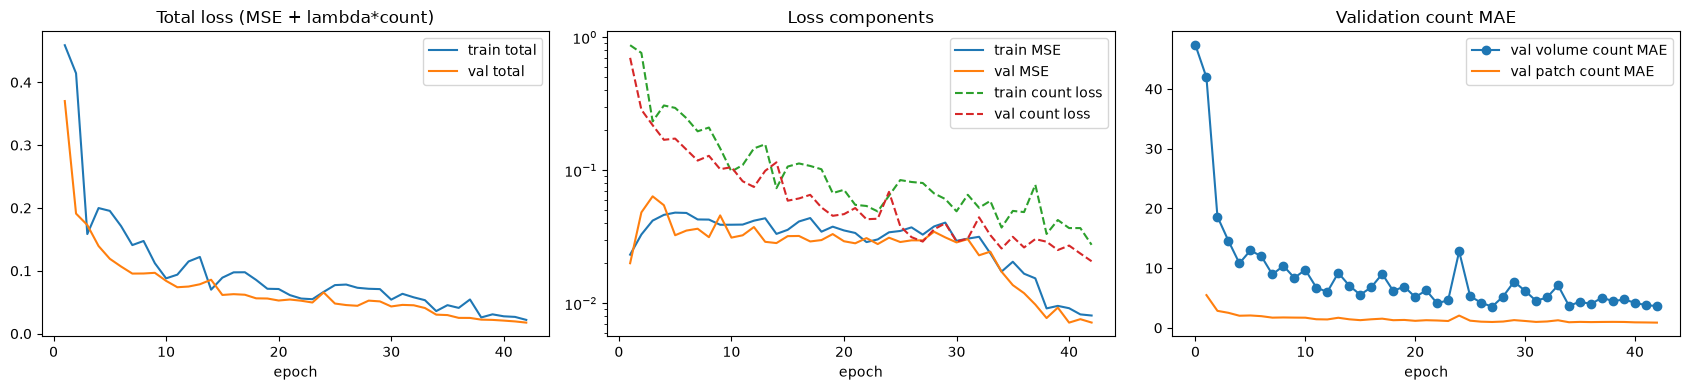

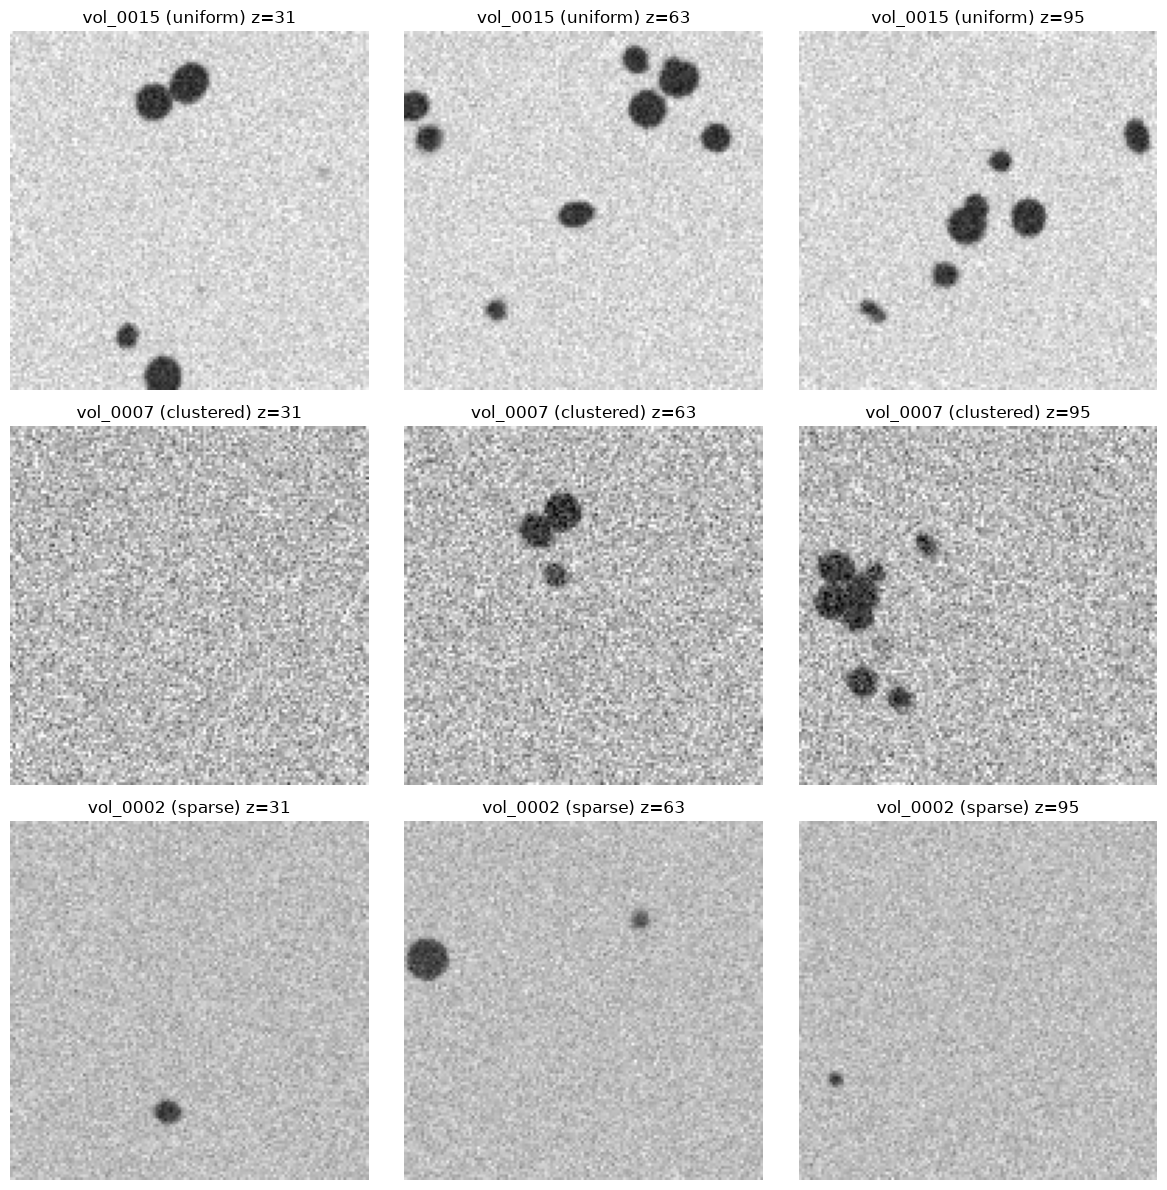

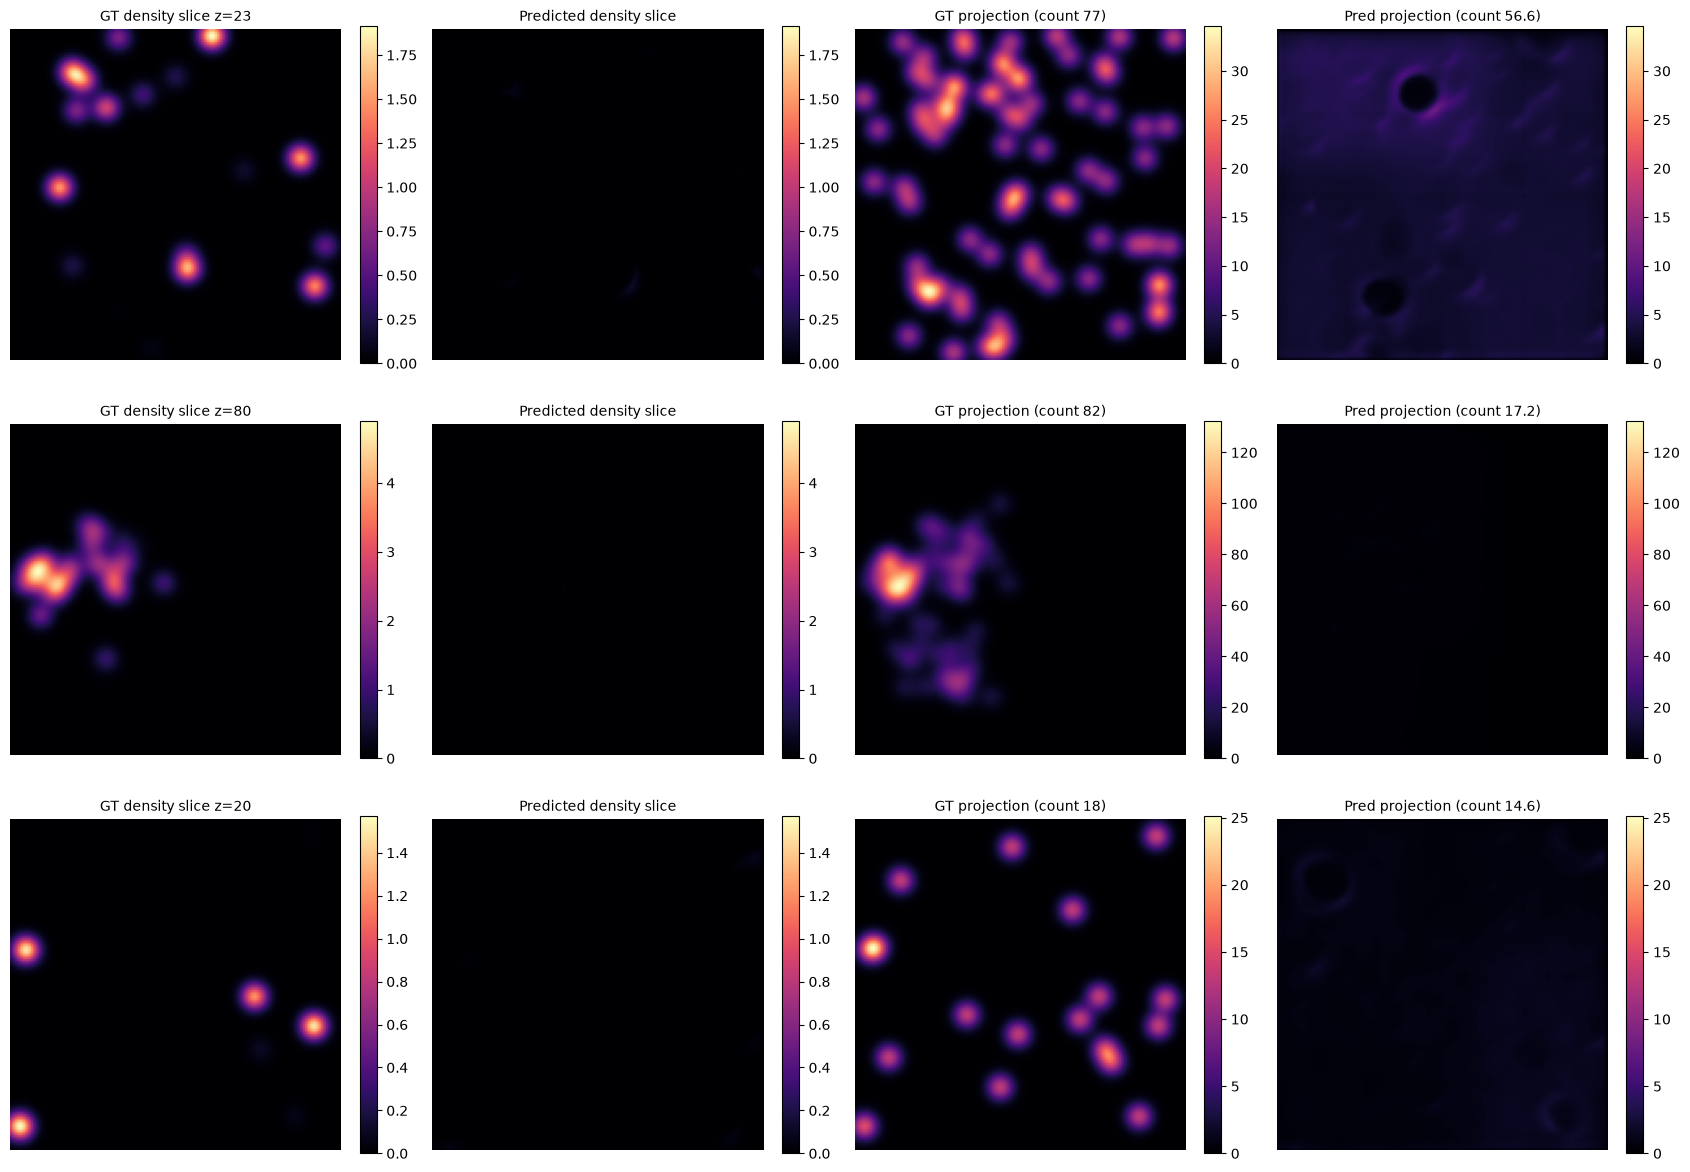

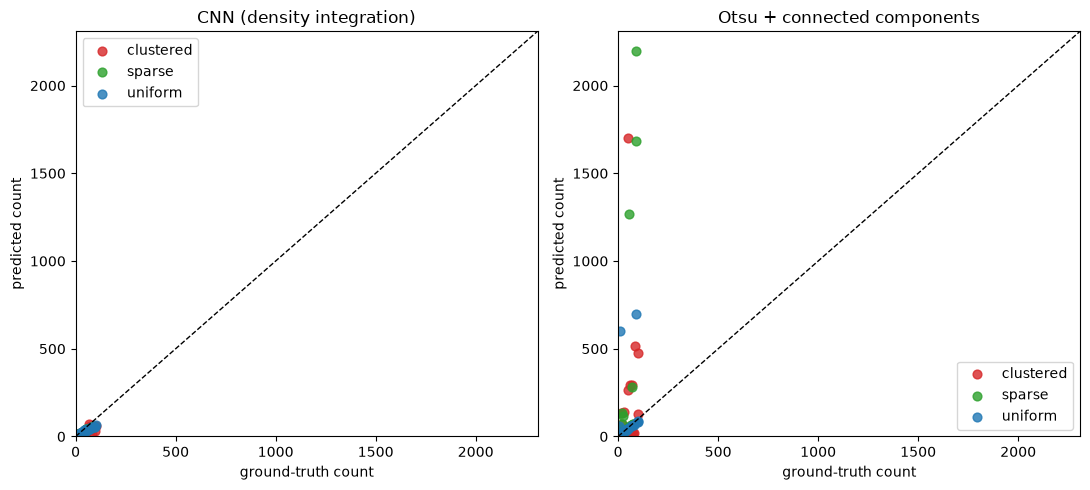

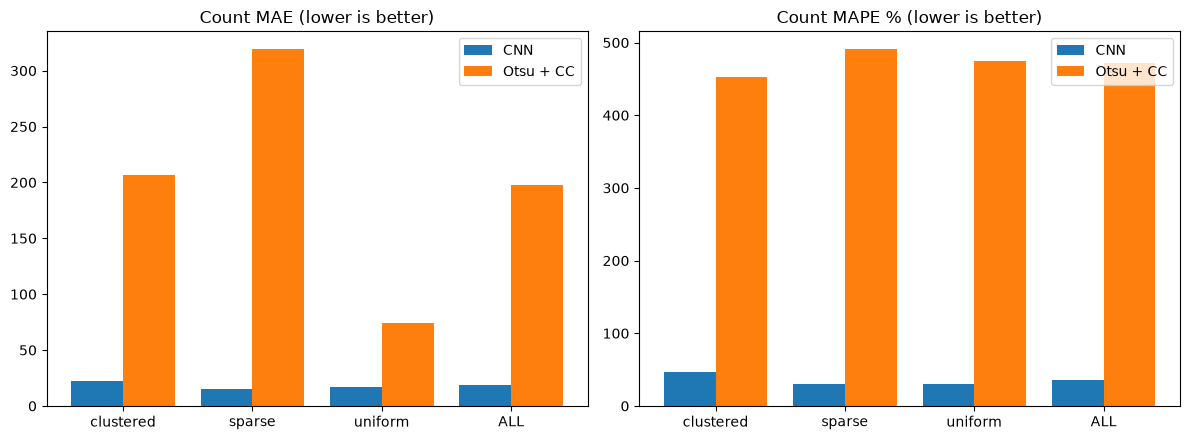

Figures saved to C:\Users\bpgod\Downloads\proejct-47\outputs\figures


In [32]:
# =====================================================================
# STEP 8 - figures
# =====================================================================
REGIME_COLORS = {"uniform": "tab:blue", "clustered": "tab:red", "sparse": "tab:green"}


def plot_training_curves(history, tag="main"):
    if history is None or len(history) == 0:
        print("No training history available.")
        return
    h = history[history["epoch"] > 0]
    fig, ax = plt.subplots(1, 3, figsize=(17, 4))
    ax[0].plot(h["epoch"], h["train_loss"], label="train total")
    ax[0].plot(h["epoch"], h["val_loss"], label="val total")
    ax[0].set_title("Total loss (MSE + lambda*count)"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["epoch"], h["train_mse"], label="train MSE"); ax[1].plot(h["epoch"], h["val_mse"], label="val MSE")
    ax[1].plot(h["epoch"], h["train_count_loss"], "--", label="train count loss")
    ax[1].plot(h["epoch"], h["val_count_loss"], "--", label="val count loss")
    ax[1].set_title("Loss components"); ax[1].set_xlabel("epoch"); ax[1].set_yscale("log"); ax[1].legend()
    ax[2].plot(history["epoch"], history["val_count_mae"], marker="o", label="val volume count MAE")
    ax[2].plot(h["epoch"], h["val_patch_count_mae"], label="val patch count MAE")
    ax[2].set_title("Validation count MAE"); ax[2].set_xlabel("epoch"); ax[2].legend()
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"{tag}_training_curves.png", dpi=130)
    plt.show()


def pick_examples(df, max_n=3):
    picks = []
    for regime in REGIMES:
        sub = df[df["regime"] == regime]
        if len(sub):
            picks.append(sub.iloc[0]["volume_id"])
    return picks[:max_n] if picks else list(df["volume_id"][:max_n])


def plot_example_slices(df, records, tag="main"):
    by_id = {r["volume_id"]: r for r in records}
    picks = pick_examples(df)
    fig, axes = plt.subplots(len(picks), 3, figsize=(12, 4 * len(picks)), squeeze=False)
    for i, vid in enumerate(picks):
        vol = np.load(by_id[vid]["path_volume"])
        for j, frac in enumerate((0.25, 0.5, 0.75)):
            z = int(frac * (vol.shape[0] - 1))
            axes[i, j].imshow(vol[z], cmap="gray", vmin=0, vmax=1)
            axes[i, j].set_title(f"{vid} ({by_id[vid]['regime']}) z={z}"); axes[i, j].axis("off")
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"{tag}_example_ct_slices.png", dpi=130)
    plt.show()


def plot_density_comparison(df, records, tag="main"):
    by_id = {r["volume_id"]: r for r in records}
    picks = pick_examples(df)
    fig, axes = plt.subplots(len(picks), 4, figsize=(17, 4 * len(picks)), squeeze=False)
    for i, vid in enumerate(picks):
        gt = np.load(by_id[vid]["path_density"]) * TARGET_SCALE
        pr = np.load(pred_path(vid, tag)) * TARGET_SCALE
        z = int(np.argmax(gt.sum(axis=(1, 2))))
        vmax = max(float(gt[z].max()), float(pr[z].max()), 1e-9)
        pmax = max(float(gt.sum(axis=0).max()), float(pr.sum(axis=0).max()), 1e-9)
        panels = [(gt[z], f"GT density slice z={z}", vmax), (pr[z], "Predicted density slice", vmax),
                  (gt.sum(axis=0), f"GT projection (count {by_id[vid]['true_count']})", pmax),
                  (pr.sum(axis=0), f"Pred projection (count {pr.sum() / TARGET_SCALE:.1f})", pmax)]
        for j, (img, title, vm) in enumerate(panels):
            im = axes[i, j].imshow(img, cmap="magma", vmin=0, vmax=vm)
            axes[i, j].set_title(title, fontsize=10); axes[i, j].axis("off")
            plt.colorbar(im, ax=axes[i, j], fraction=0.046)
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"{tag}_density_gt_vs_pred.png", dpi=130)
    plt.show()


def plot_count_scatter(df, tag="main"):
    fig, ax = plt.subplots(1, 2, figsize=(11, 5))
    top = max(df["true_count"].max(), df["cnn_count"].max(), df["cc_count"].max()) * 1.05
    for a, col, name in ((ax[0], "cnn_count", "CNN (density integration)"), (ax[1], "cc_count", "Otsu + connected components")):
        for regime, sub in df.groupby("regime"):
            a.scatter(sub["true_count"], sub[col], c=REGIME_COLORS.get(regime, "k"), label=regime, s=40, alpha=0.8)
        a.plot([0, top], [0, top], "k--", lw=1)
        a.set_xlim(0, top); a.set_ylim(0, top); a.set_xlabel("ground-truth count"); a.set_ylabel("predicted count")
        a.set_title(name); a.legend()
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"{tag}_count_scatter.png", dpi=130)
    plt.show()


def plot_method_comparison(table, tag="main"):
    t = table.copy()
    x = np.arange(len(t))
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
    for a, metric, title in ((ax[0], "MAE", "Count MAE (lower is better)"), (ax[1], "MAPE_%", "Count MAPE % (lower is better)")):
        a.bar(x - 0.2, t[f"CNN_{metric}"], 0.4, label="CNN")
        a.bar(x + 0.2, t[f"CC_{metric}"], 0.4, label="Otsu + CC")
        a.set_xticks(x); a.set_xticklabels(t["group"]); a.set_title(title); a.legend()
    plt.tight_layout()
    fig.savefig(FIG_DIR / f"{tag}_cnn_vs_cc.png", dpi=130)
    plt.show()


plot_training_curves(history_df)
plot_example_slices(results_df, test_records)
plot_density_comparison(results_df, test_records)
plot_count_scatter(results_df)
plot_method_comparison(regime_table)
print(f"Figures saved to {FIG_DIR}")

### Experiments A-D

Experiment B - performance by spatial regime (see table above, saved to results_by_regime.csv)
Experiment A - CNN vs classical CC across noise levels:


,noise_level,gaussian_sigma,poisson_photons,CNN_MAE,CNN_MAPE_%,CC_MAE,CC_MAPE_%,n_volumes
0,none,0.00,0,21.673,57.169,17.05,24.363,20
1,low,0.02,2000,21.593,40.941,23.65,153.576,20
2,medium,0.05,500,21.305,40.973,279.55,1017.028,20
3,high,0.10,150,21.224,41.151,607.75,817.740,20
4,very_high,0.15,80,21.419,41.801,82.35,155.058,20


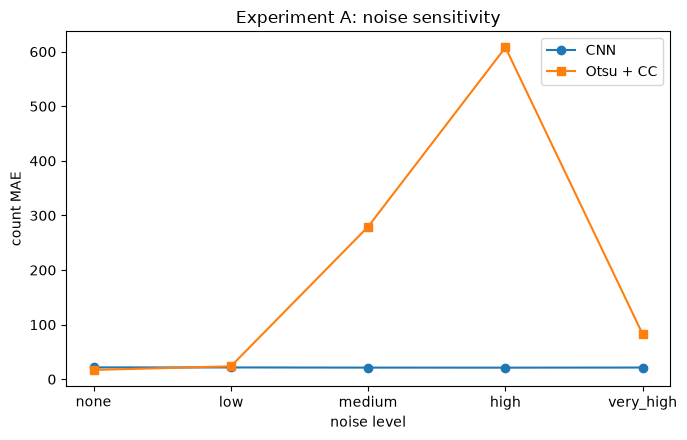

Experiment C not run (RUN_EXPERIMENT_C = False; it trains one extra model per sigma).
Experiment D not run (RUN_EXPERIMENT_D = False; it trains an extra model on counts <= 60).
Project 40 detect-then-count comparison: NOT implemented (no Project 40 detector code was supplied).


In [34]:
# =====================================================================
# STEP 8 - experiments A-D  (A runs by default; C and D retrain models -> enable via RUN_EXPERIMENT_* flags)
# =====================================================================
def render_from_mask(rec, level, level_index=0):
    # re-render a test volume from its saved pore mask with a different noise level (deterministic)
    mask = np.load(rec["path_mask"]).astype(bool)
    rng = make_rng(300, int(rec["volume_id"].split("_")[1]), level_index)
    return render_ct(mask, float(rec["matrix_intensity"]), float(rec["pore_intensity"]), float(rec["edge_blur_sigma"]),
                     level["gaussian_sigma"], level["poisson_photons"], rng)


def run_experiment_A(model, records):
    # CNN vs classical CC across noise levels (same pore geometry, different noise)
    rows = []
    for li, (name, level) in enumerate(EXP_A_NOISE_LEVELS.items()):
        fn = lambda rec, level=level, li=li: render_from_mask(rec, level, li)
        cc = run_classical_baseline(records, volume_fn=fn)
        cnn, store = run_cnn_inference(model, records, volume_fn=fn, compute_ssim=False)
        m = cnn.merge(cc, on="volume_id")
        c1, c2 = count_metrics(m["true_count"], m["cnn_count"]), count_metrics(m["true_count"], m["cc_count"])
        rows.append({"noise_level": name, "gaussian_sigma": level["gaussian_sigma"], "poisson_photons": level["poisson_photons"],
                     "CNN_MAE": c1["MAE"], "CNN_MAPE_%": c1["MAPE_%"], "CC_MAE": c2["MAE"], "CC_MAPE_%": c2["MAPE_%"],
                     "n_volumes": len(m)})
    return pd.DataFrame(rows)


def evaluate_with_sigma(model, records, sigma, tag):
    cnn, store = run_cnn_inference(model, records, density_sigma=sigma, tag=tag, compute_ssim=True)
    row = summarize_group(cnn, store, f"sigma={sigma}")
    row["sigma"] = sigma
    return row


def run_experiment_C(main_model):
    rows = []
    for sigma in EXP_C_SIGMAS:
        if abs(sigma - DENSITY_SIGMA) < 1e-9:
            m = main_model
        else:
            m, _ = train_model(train_records, val_records, tag=f"sigma_{sigma}", density_sigma=sigma)
        rows.append(evaluate_with_sigma(m, test_records, sigma, f"sigma_{sigma}"))
    return pd.DataFrame(rows)


def run_experiment_D():
    tr = [r for r in train_records if r["true_count"] <= EXP_D_TRAIN_MAX]
    va = [r for r in val_records if r["true_count"] <= EXP_D_TRAIN_MAX]
    te = [r for r in test_records if r["true_count"] > EXP_D_TRAIN_MAX]
    print(f"Experiment D: train {len(tr)} / val {len(va)} volumes with count <= {EXP_D_TRAIN_MAX}; test {len(te)} volumes with count > {EXP_D_TRAIN_MAX}")
    if len(tr) == 0 or len(va) == 0 or len(te) == 0:
        print("Experiment D skipped: not enough volumes in one of the pools (expected with the 6-volume pilot).")
        return None
    m, _ = train_model(tr, va, tag="extrapolation")
    cnn, store = run_cnn_inference(m, te, tag="extrapolation")
    cc = run_classical_baseline(te)
    merged = cnn.merge(cc, on="volume_id")
    return pd.DataFrame([summarize_group(merged, store, f"count>{EXP_D_TRAIN_MAX} (trained on <= {EXP_D_TRAIN_MAX})")])


# ---- Experiment B: regimes (already computed above from the main test results) ----
print("Experiment B - performance by spatial regime (see table above, saved to results_by_regime.csv)")

# ---- Experiment A ----
if RUN_EXPERIMENT_A:
    exp_a = run_experiment_A(model, test_records[:EXP_A_MAX_VOLUMES])
    exp_a.to_csv(RESULT_DIR / "experiment_A_noise.csv", index=False)
    print("Experiment A - CNN vs classical CC across noise levels:")
    display(exp_a.round(3))
    fig, ax = plt.subplots(figsize=(7, 4.5))
    ax.plot(exp_a["noise_level"], exp_a["CNN_MAE"], marker="o", label="CNN")
    ax.plot(exp_a["noise_level"], exp_a["CC_MAE"], marker="s", label="Otsu + CC")
    ax.set_xlabel("noise level"); ax.set_ylabel("count MAE"); ax.set_title("Experiment A: noise sensitivity"); ax.legend()
    plt.tight_layout()
    fig.savefig(FIG_DIR / "experiment_A_noise.png", dpi=130)
    plt.show()
else:
    print("Experiment A disabled (RUN_EXPERIMENT_A = False).")

# ---- Experiment C ----
if RUN_EXPERIMENT_C:
    exp_c = run_experiment_C(model)
    exp_c.to_csv(RESULT_DIR / "experiment_C_sigma.csv", index=False)
    print("Experiment C - Gaussian target sigma sensitivity:")
    display(exp_c.round(4))
else:
    print("Experiment C not run (RUN_EXPERIMENT_C = False; it trains one extra model per sigma).")

# ---- Experiment D ----
if RUN_EXPERIMENT_D:
    exp_d = run_experiment_D()
    if exp_d is not None:
        exp_d.to_csv(RESULT_DIR / "experiment_D_extrapolation.csv", index=False)
        print("Experiment D - count extrapolation:")
        display(exp_d.round(4))
else:
    print("Experiment D not run (RUN_EXPERIMENT_D = False; it trains an extra model on counts <= 60).")

print("Project 40 detect-then-count comparison: NOT implemented (no Project 40 detector code was supplied).")